# iTransformer — FS04_METALS_CU (Five metals + Copper history) — Kaggle standalone

**Mục tiêu:** dự báo `Copper(t)` 1 phiên tới bằng iTransformer, đầu vào **đúng 5 kênh** từ bộ `FS04_METALS_CU` trong báo cáo Module 1 của Khoa: `Copper, Aluminium, Tin, Silver, Gold`. Mỗi cửa sổ có **22 phiên `t−22 ... t−1`**, không lấy dữ liệu phiên `t` làm input.

**Nguồn phương pháp:** `iTransformer_vs_SA_LSTM_K5_Fair_FINAL_Colab.ipynb` (kiến trúc iTransformer) và `17-11-Copper-NonSA-Fair-Full-Protocol-V20.ipynb` / `18-11-Copper_NonSA_V22_WTI...` (4 splits, 3 schemes, train-only scaler), kết hợp mã FS theo `Mythos_Copper_Module1_V20_V26.md`.

**Kaggle:** Bật **Accelerator → GPU**, thêm dataset chứa `dataset_9_commodities_daily.csv` qua **Add Input**, sau đó bấm **Run All**. **FULL** chạy 4 tỷ lệ × 3 strategies × (DIRECT, RESIDUAL + Naive), **QUICK** để thử pipeline. Mỗi notebook chỉ chạy **một bộ FS** để dễ theo dõi, lưu tiến độ từng job trong `/kaggle/working/iTransformer_Module1_6FS/`.

**Chế độ dự báo:** DIRECT dự báo mức giá chuẩn hóa; RESIDUAL học `Δy_t = y_t − y_(t−1)` trên thang Copper đã chuẩn hóa, sau đó khôi phục `ŷ_t = y_(t−1) + Δŷ_t` rồi inverse-transform. Cả hai là **hai lần train riêng** với kiến trúc giống nhau.

**Kiến trúc:** Inverted Embedding biến chuỗi `(22,K)` thành `(K,48)`; **2 encoders**, **4 heads**, key_dim=12, FFN 96→48 (GELU), encoder dropout 0.1, Flatten `(K×48)` → Dense(32,GELU) → Dropout(0.1) → Dense(1,linear). Với `K=1`, attention giữa biến chỉ còn một token: vẫn chạy đúng builder nhưng không có quan hệ liên biến để học.

**Giao thức:** 80/20 · 90/10 · 92.5/7.5 · 95/5; Expanding / Rolling-756 / Recency weighted (half-life=252); validation = 10% cuối của đoạn trước test; scaler được **fit chỉ trên phần train trước validation**; Adam lr=0.0003, batch=64, seed=42, patience=9 và tối đa **65 epochs** để cùng ngân sách tối đa Non-SA V20 (**iTransformer K5 FINAL trước đây dùng 100; có thể đổi `EPOCHS` thành 100 nếu cần so với bản đó**).

**Chú ý công bằng:** 6 notebook dùng chung bộ dòng CSV hợp lệ trên union `Copper, WTI, Gold, Silver, Aluminium, Tin`, để giữ cùng lịch test. `FS03` và `FS05` không đưa Copper vào tensor model; tuy nhiên nhánh RESIDUAL vẫn sử dụng **Copper(t−1) ở phép cộng cuối**, đúng quy tắc residual của Module 1. Do đó chỉ gọi hai bộ này là *không có Copper trong input network*, không phải *toàn hệ không dùng Copper lịch sử*. Kiểm tra `SHA256` và `test_start_date` trùng với kết quả Khoa trước khi so sánh số liệu.

---


## 1. Thiết lập và cấu hình chạy

In [1]:
FEATURE_SET_ID = 'FS04_METALS_CU'
FEATURES = ['Copper', 'Aluminium', 'Tin', 'Silver', 'Gold']
from pathlib import Path
import os, gc, json, time, zipfile, hashlib, shutil, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score
import tensorflow as tf
from IPython.display import display

# ================================================================
# PHẦN CÓ THỂ CHỈNH TRƯỚC KHI CHẠY KAGGLE
# ================================================================
MODE = 'FULL'  # 'FULL': 4 splits × 3 schemes × (DIRECT, RESIDUAL, Naive)
               # 'QUICK': chạy smoke test 80/20 Expanding 2 epochs
CUSTOM_CSV_PATH = ''  # Nếu tự upload CSV, điền path tuyệt đối ở đây.
EXPECTED_SHA256 = ''  # Nếu đã khóa fingerprint CSV, điền vào; mặc định in SHA để đối chiếu.
SAVE_TRAINED_MODELS = False  # True lưu 24 file .keras (nặng); mặc định chỉ CSV / biểu đồ.
INCLUDE_MODELS_IN_ZIP = False

LOOKBACK, HORIZON = 22, 1
TARGET = 'Copper'
SEED = 42
BATCH_SIZE = 64
RATIOS = (0.80, 0.90, 0.925, 0.95) if MODE == 'FULL' else (0.80,)
SCHEMES = ('expanding', 'rolling_756', 'recency_weighted') if MODE == 'FULL' else ('expanding',)
RECENCY_HALF_LIFE = 252
EPOCHS = 65 if MODE == 'FULL' else 2  # Khớp ngân sách tối đa V20 Non-SA; bản iTransformer K5 trước dùng 100.
PATIENCE = 9 if MODE == 'FULL' else 1
OBJECTIVES = ('direct','residual')

# Kiến trúc iTransformer V20/K5 gốc, chỉ thay K=len(FEATURES) giữa FS01..FS06.
EMBED_DIM = 48
ENCODER_LAYERS = 2
ATTENTION_HEADS = 4
HEAD_KEY_DIM = 12
FF_DIM = 96
ENCODER_DROPOUT = 0.10
HEAD_UNITS = 32
LR = 0.0003
CLIPNORM = 1.0

# Các cột chung để lọc thiếu GIỐNG HỆT giữa 6 notebooks và giữ đồng nhất ngày test.
DATA_UNION_COLUMNS = ['Copper', 'WTI', 'Gold', 'Silver', 'Aluminium', 'Tin']
SOURCE_DATASET_NAME = 'dataset_9_commodities_daily.csv'

assert MODE in ('FULL','QUICK') and HORIZON==1 and LOOKBACK==22
assert TARGET in DATA_UNION_COLUMNS and set(FEATURES).issubset(DATA_UNION_COLUMNS)
assert len(FEATURES)==len(set(FEATURES))

BASE = Path('/kaggle/working') if Path('/kaggle/working').is_dir() else Path.cwd()
tf.keras.utils.set_random_seed(SEED)
for gpu in tf.config.list_physical_devices('GPU'):
    try: tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError: pass
print('TensorFlow:', tf.__version__, '| GPU:', tf.config.list_physical_devices('GPU'))
print('Feature set:', FEATURE_SET_ID, '| features:', FEATURES)
print('Run:', MODE, '| epochs:', EPOCHS, '| splits:', RATIOS, '| schemes:', SCHEMES)


TensorFlow: 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Feature set: FS04_METALS_CU | features: ['Copper', 'Aluminium', 'Tin', 'Silver', 'Gold']
Run: FULL | epochs: 65 | splits: (0.8, 0.9, 0.925, 0.95) | schemes: ('expanding', 'rolling_756', 'recency_weighted')


## 2. Tìm CSV đúng, kiểm toán dữ liệu & khóa cấu hình

In [2]:
# DATASET: chọn đúng CSV của Module 1 — tuyệt đối không dùng file giả lập để báo cáo.
candidates = (
    ([Path(CUSTOM_CSV_PATH).expanduser()] if CUSTOM_CSV_PATH.strip() else [])
    + [Path('/kaggle/input/datasets/lancelot71000/dataset-9-commodities-daily') / SOURCE_DATASET_NAME,
       Path('/kaggle/input/dataset-9-commodities-daily') / SOURCE_DATASET_NAME,
       Path.cwd() / SOURCE_DATASET_NAME,
       Path('data/processed') / SOURCE_DATASET_NAME]
)
existing = [p for p in candidates if p.is_file()]
if existing:
    data_path=existing[0]
else:
    discovered = sorted(Path('/kaggle/input').rglob(SOURCE_DATASET_NAME)) if Path('/kaggle/input').is_dir() else []
    if len(discovered)>1:
        raise RuntimeError('Tìm thấy nhiều file CSV trùng tên. Hãy điền CUSTOM_CSV_PATH: '+str(discovered))
    data_path=discovered[0] if len(discovered)==1 else None
if data_path is None:
    raise FileNotFoundError('Chưa gắn Kaggle Dataset chứa '+SOURCE_DATASET_NAME+'. Vào Add Input / Add Data, tìm Dataset 9 commodities daily; hoặc thiết lập CUSTOM_CSV_PATH.')

DATA_SHA256=hashlib.sha256(Path(data_path).read_bytes()).hexdigest()
if EXPECTED_SHA256 and DATA_SHA256.lower()!=EXPECTED_SHA256.lower():
    raise RuntimeError('SHA256 CSV khác kỳ vọng: '+DATA_SHA256)
raw=pd.read_csv(data_path)
needed=['Date']+DATA_UNION_COLUMNS
missing=sorted(set(needed)-set(raw.columns))
if missing: raise KeyError('CSV không đủ cột sử dụng chung FS01..FS06: '+str(missing))
raw['Date']=pd.to_datetime(raw['Date'],errors='coerce')
if raw['Date'].isna().any() or raw['Date'].duplicated().any():
    raise ValueError('Date thiếu, không hợp lệ hoặc trùng — phải sửa CSV trước khi chạy.')
raw=raw.sort_values('Date').reset_index(drop=True)
for col in DATA_UNION_COLUMNS: raw[col]=pd.to_numeric(raw[col],errors='coerce')
quality=pd.DataFrame({'feature':DATA_UNION_COLUMNS,
                      'missing':[int(raw[c].isna().sum()) for c in DATA_UNION_COLUMNS],
                      'nonpositive':[int((raw[c]<=0).sum()) for c in DATA_UNION_COLUMNS]})
# Giống nguyên tắc Module 1: tất cả sáu bộ FS dùng cùng dòng, không tự fill bằng tương lai.
data=raw.dropna(subset=DATA_UNION_COLUMNS).reset_index(drop=True)
if len(data)<500: raise ValueError('Dữ liệu quá ngắn sau khi lọc union columns.')
if not np.isfinite(data[DATA_UNION_COLUMNS].to_numpy(np.float64)).all():
    raise ValueError('Có dữ liệu NaN/Inf.')
if not (data[DATA_UNION_COLUMNS]>0).to_numpy().all():
    raise ValueError('Có giá <=0. Cần kiểm toán dữ liệu trước khi fit.')

# RUN_ID chứa cả SHA CSV và mọi setting quyết định kết quả => không trộn các job khác nhau.
RUN_CONFIG={
    'script':'itransformer_six_fs_module1_v1', 'feature_set':FEATURE_SET_ID,
    'features':FEATURES, 'target':TARGET, 'dataset':str(data_path), 'data_sha256':DATA_SHA256,
    'num_rows':len(data), 'lookback':LOOKBACK, 'horizon':HORIZON,
    'ratios':RATIOS, 'schemes':SCHEMES, 'seed':SEED, 'batch':BATCH_SIZE,
    'max_epochs':EPOCHS, 'patience':PATIENCE, 'objectives':OBJECTIVES,
    'recency_half_life':RECENCY_HALF_LIFE, 'embed':EMBED_DIM, 'encoders':ENCODER_LAYERS,
    'heads':ATTENTION_HEADS, 'key_dim':HEAD_KEY_DIM, 'ff_dim':FF_DIM,
    'encoder_dropout':ENCODER_DROPOUT, 'head_units':HEAD_UNITS, 'lr':LR,
    'clipnorm':CLIPNORM, 'data_union_cols':DATA_UNION_COLUMNS
}
run_hash=hashlib.sha256(json.dumps(RUN_CONFIG,sort_keys=True).encode()).hexdigest()[:12]
RUN_KEY=f'{MODE}_{FEATURE_SET_ID}_s{SEED}_sha{DATA_SHA256[:8]}_{run_hash}'
OUT=BASE/'iTransformer_Module1_6FS'/FEATURE_SET_ID/RUN_KEY
for d in ['jobs','figures','models']:(OUT/d).mkdir(parents=True,exist_ok=True)
(OUT/'config.json').write_text(json.dumps(RUN_CONFIG,ensure_ascii=False,indent=2),encoding='utf-8')
quality.to_csv(OUT/'data_quality.csv',index=False)
print('Dataset:',data_path,'| SHA256:',DATA_SHA256)
print('N=',len(data),'| start=',data.Date.iloc[0].date(),'| end=',data.Date.iloc[-1].date(),
      '| removed=',len(raw)-len(data),'| output:',OUT)
if len(data)!=2710:
    print('WARNING: Số dòng khác N=2710 được mô tả trong README Khoa. So sánh cần kiểm tra lại ngày test!')
if len(raw)!=len(data):
    print('WARNING: Một số dòng có missing ở union 6 biến đã bị loại. Hãy đối chiếu chính xác preprocessing của nhóm.')
display(quality)


Dataset: /kaggle/input/datasets/tvi3001/dataset-9-commodities-daily/dataset_9_commodities_daily.csv | SHA256: a761a9082de36ad8724597ff1518e24bbf1a61676bd3164676e7f4218d275d83
N= 2710 | start= 2016-01-13 | end= 2026-11-13 | removed= 0 | output: /kaggle/working/iTransformer_Module1_6FS/FS04_METALS_CU/FULL_FS04_METALS_CU_s42_shaa761a908_bd12631cf50d


,feature,missing,nonpositive
0,Copper,0,0
1,WTI,0,0
2,Gold,0,0
3,Silver,0,0
4,Aluminium,0,0
5,Tin,0,0


## 3. Chia thời gian, tạo cửa sổ 22 phiên, scaler fit trên train

In [3]:
def make_context(frame, ratio, scheme):
    if scheme not in SCHEMES: raise ValueError('Unknown scheme: '+scheme)
    n=len(frame); split=int(n*float(ratio)); val_start=int(split*0.90)
    fit_start=max(0,val_start-756) if scheme=='rolling_756' else 0
    if not (LOOKBACK+40 < val_start-fit_start and val_start<split<n):
        raise ValueError('Không đủ mẫu train/val/test cho lookback.')

    # Chỉ train để fit MinMax, sau đó transform nguyên timeline bằng cùng scaler.
    xsc=MinMaxScaler().fit(frame.iloc[fit_start:val_start][FEATURES])
    ysc=MinMaxScaler().fit(frame.iloc[fit_start:val_start][[TARGET]])
    x=xsc.transform(frame[FEATURES]).astype(np.float32)
    y=ysc.transform(frame[[TARGET]]).ravel().astype(np.float32)
    
    def block(start,end,train=False):
        ids=np.arange(max(start,LOOKBACK),end,dtype=np.int64)
        if train: ids=ids[ids-LOOKBACK>=fit_start]
        if not len(ids): raise ValueError('Không đủ cửa sổ ở '+str((start,end)))
        ind=ids[:,None]-LOOKBACK+np.arange(LOOKBACK)[None,:]
        assert np.all(ind<ids[:,None]), 'Leakage: input không được chứa phiên t'
        X=x[ind]
        return {'idx':ids,'X':X,'y':y[ids],'prev':y[ids-1],
                'date':frame.Date.iloc[ids].to_numpy()}
    train=block(fit_start,val_start,True)
    val=block(val_start,split)
    test=block(split,n)
    for name,b in [('train',train),('val',val),('test',test)]:
        assert b['X'].shape[1:]==(LOOKBACK,len(FEATURES))
        assert np.isfinite(b['X']).all() and np.isfinite(b['y']).all() and np.isfinite(b['prev']).all(),name
        # Chỉ FS chứa Copper mới được phép so sánh channel Copper với baseline y(t-1).
        if TARGET in FEATURES:
            j=FEATURES.index(TARGET)
            assert np.allclose(b['X'][:,-1,j],b['prev'],atol=2e-6,rtol=1e-6)
    assert train['idx'][-1]<val['idx'][0]<test['idx'][0]
    assert xsc.n_samples_seen_==val_start-fit_start
    return {'train':train,'val':val,'test':test,'xsc':xsc,'ysc':ysc,
            'ratio':float(ratio),'scheme':scheme,'split':split,
            'fit_start':fit_start,'val_start':val_start, 'features':FEATURES}

for sch in SCHEMES:
    ctx=make_context(data,RATIOS[0],sch)
    print(sch,'| train',ctx['train']['X'].shape,'| val',ctx['val']['X'].shape,
          '| test',ctx['test']['X'].shape,'| test start',pd.Timestamp(ctx['test']['date'][0]).date())
if TARGET not in FEATURES:
    print('FS EXO: Copper KHÔNG nằm trong tensor X; ở RESIDUAL chỉ dùng y(t-1) ở bước cộng khôi phục.')
print('PASS: fit train-only, K động, cửa sổ đúng 22 phiên, no future target leakage.')


expanding | train (1929, 22, 5) | val (217, 22, 5) | test (542, 22, 5) | test start 2024-10-07
rolling_756 | train (734, 22, 5) | val (217, 22, 5) | test (542, 22, 5) | test start 2024-10-07
recency_weighted | train (1929, 22, 5) | val (217, 22, 5) | test (542, 22, 5) | test start 2024-10-07
PASS: fit train-only, K động, cửa sổ đúng 22 phiên, no future target leakage.


## 4. iTransformer linh hoạt theo số biến K

In [4]:
def build_itransformer(n_features=len(FEATURES)):
    # Inverted Transformer: token theo biến (K), từng token chứa 22 phiên quá khứ.
    inp=tf.keras.Input(shape=(LOOKBACK,n_features),name='past_prices_22xK')
    x=tf.keras.layers.Permute((2,1),name='invert_to_variable_tokens')(inp)  # (B,K,22)
    x=tf.keras.layers.Dense(EMBED_DIM,name='variable_embedding')(x)          # (B,K,48)
    for i in range(ENCODER_LAYERS):
        a=tf.keras.layers.MultiHeadAttention(num_heads=ATTENTION_HEADS,
            key_dim=HEAD_KEY_DIM,dropout=ENCODER_DROPOUT,
            name=f'encoder{i+1}_mha')(x,x)
        a=tf.keras.layers.Dropout(ENCODER_DROPOUT,name=f'encoder{i+1}_attn_drop')(a)
        x=tf.keras.layers.LayerNormalization(epsilon=1e-6,name=f'encoder{i+1}_add_norm1')(
            tf.keras.layers.Add(name=f'encoder{i+1}_residual1')([x,a]))
        y=tf.keras.layers.Dense(FF_DIM,activation='gelu',name=f'encoder{i+1}_ff1')(x)
        y=tf.keras.layers.Dropout(ENCODER_DROPOUT,name=f'encoder{i+1}_ff_drop')(y)
        y=tf.keras.layers.Dense(EMBED_DIM,name=f'encoder{i+1}_ff2')(y)
        x=tf.keras.layers.LayerNormalization(epsilon=1e-6,name=f'encoder{i+1}_add_norm2')(
            tf.keras.layers.Add(name=f'encoder{i+1}_residual2')([x,y]))
    x=tf.keras.layers.Flatten(name='flatten_K_times_48')(x)  # K*48, KHÔNG hardcode 240.
    x=tf.keras.layers.Dense(HEAD_UNITS,activation='gelu',name='head_dense_gelu')(x)
    x=tf.keras.layers.Dropout(ENCODER_DROPOUT,name='head_dropout')(x)
    out=tf.keras.layers.Dense(1,activation='linear',name='head_linear')(x)
    model=tf.keras.Model(inp,out,name=f'iTransformer_{FEATURE_SET_ID}')
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=LR,clipnorm=CLIPNORM),
                  loss='mse')
    return model

probe=build_itransformer()
assert probe.input_shape==(None,LOOKBACK,len(FEATURES)) and probe.output_shape==(None,1)
assert probe.get_layer('variable_embedding').output.shape[-2:]==(len(FEATURES),EMBED_DIM)
print('iTransformer:',FEATURE_SET_ID,'| n_features=',len(FEATURES),'| params=',probe.count_params())
print('Head flatten:',len(FEATURES),'×',EMBED_DIM,'=',len(FEATURES)*EMBED_DIM)
if len(FEATURES)==1:
    print('Lưu ý FS01: chỉ có 1 token => attention không học tương tác liên biến; vẫn là iTransformer cùng builder.')
del probe
tf.keras.backend.clear_session()
gc.collect()


iTransformer: FS04_METALS_CU | n_features= 5 | params= 46769
Head flatten: 5 × 48 = 240


0

## 5. DIRECT / RESIDUAL, train, metrics, checkpoint

In [5]:
def set_seed(seed=SEED):
    tf.keras.backend.clear_session()
    gc.collect()
    tf.keras.utils.set_random_seed(int(seed))

def train_weights(n,scheme):
    if scheme!='recency_weighted': return None
    age=np.arange(n-1,-1,-1,dtype=np.float64)
    weights=np.exp(-np.log(2)*age/RECENCY_HALF_LIFE)
    return (weights/weights.mean()).astype(np.float32)

def target_for(block,objective):
    if objective=='direct': return block['y']
    if objective=='residual': return block['y']-block['prev']
    raise ValueError(objective)

def restore_norm(block,nn_predictions,objective):
    pred=np.asarray(nn_predictions,dtype=np.float64).reshape(-1)
    return pred+block['prev'] if objective=='residual' else pred

def inverse_y(ctx,norm_values):
    return ctx['ysc'].inverse_transform(np.asarray(norm_values,dtype=float).reshape(-1,1)).ravel()

def fit_one(ctx,objective):
    set_seed(SEED)
    net=build_itransformer()
    tr,va,te=ctx['train'],ctx['val'],ctx['test']
    callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',patience=PATIENCE,restore_best_weights=True)]
    start=time.monotonic()
    history=net.fit(tr['X'],target_for(tr,objective),
        sample_weight=train_weights(len(tr['idx']),ctx['scheme']),
        validation_data=(va['X'],target_for(va,objective)),
        batch_size=BATCH_SIZE,epochs=EPOCHS,shuffle=False,
        callbacks=callbacks,verbose=0)
    val_norm=restore_norm(va,net.predict(va['X'],verbose=0),objective)
    test_norm=restore_norm(te,net.predict(te['X'],verbose=0),objective)
    if SAVE_TRAINED_MODELS:
        model_path=OUT/'models'/f'r{int(round(ctx["ratio"]*1000)):04d}_{ctx["scheme"]}_{objective}.keras'
        tmp_path=model_path.with_name(model_path.stem+'.temp.keras')
        net.save(tmp_path)
        os.replace(tmp_path,model_path)
    elapsed=time.monotonic()-start
    hist_df=pd.DataFrame({'epoch':np.arange(1,len(history.history['loss'])+1),
        'loss':history.history['loss'],'val_loss':history.history['val_loss']})
    info={'epochs_run':len(hist_df), 'best_epoch':int(np.argmin(hist_df['val_loss'])+1),
          'fit_seconds':float(elapsed),'params':int(net.count_params())}
    del net
    set_seed(SEED)
    return val_norm,test_norm,info,hist_df

def metric_row(ctx,model,val_norm,test_norm,info):
    te,va=ctx['test'],ctx['val']
    y=inverse_y(ctx,te['y']);pred=inverse_y(ctx,test_norm)
    naive=inverse_y(ctx,te['prev']); yv=inverse_y(ctx,va['y'])
    predv=inverse_y(ctx,val_norm)
    error=y-pred; naerr=y-naive
    delta_true=y-naive; delta_pred=pred-naive
    mae=float(np.mean(np.abs(error))); rmse=float(np.sqrt(np.mean(error**2)))
    naivemae=float(np.mean(np.abs(naerr)))
    row={
      'feature_set':FEATURE_SET_ID,'feature_names': '|'.join(FEATURES),
      'K':len(FEATURES),'ratio':ctx['ratio'],'scheme':ctx['scheme'],
      'model':model,'seed':SEED,'mode':MODE,'run_key':RUN_KEY,'data_sha256':DATA_SHA256,
      'n_train':len(ctx['train']['idx']),'n_val':len(va['idx']),'n_test':len(te['idx']),
      'mae':mae,'rmse':rmse,'mse':float(np.mean(error**2)),
      'mape_pct':float(100*np.mean(np.abs(error)/np.abs(y))) if np.all(y!=0) else np.nan,
      'r2':float(r2_score(y,pred)) if len(y)>1 else np.nan,
      'directional_accuracy_pct':float(100*np.mean(np.sign(delta_pred)==np.sign(delta_true))),
      'mae_naive':naivemae,
      'skill_vs_naive_pct':float(100*(naivemae-mae)/naivemae) if naivemae>0 else np.nan,
      'val_mae':float(np.mean(np.abs(yv-predv))),
      'pred_delta_std':float(np.std(delta_pred)),
      'true_delta_std':float(np.std(delta_true)),
      'test_start_date':str(pd.Timestamp(te['date'][0]).date()),
      'test_end_date':str(pd.Timestamp(te['date'][-1]).date()),
      'train_scaler_start_date':str(data.Date.iloc[ctx['fit_start']].date()),
      'train_scaler_end_date':str(data.Date.iloc[ctx['val_start']-1].date()),
      'max_epochs':EPOCHS,'learning_rate':LR
    }
    row.update(info)
    predictions=pd.DataFrame({
       'Date':pd.to_datetime(te['date']),'feature_set':FEATURE_SET_ID,
       'ratio':ctx['ratio'],'scheme':ctx['scheme'],'model':model,'seed':SEED,
       'run_key':RUN_KEY,'actual':y,'pred':pred,'naive':naive,
       'actual_delta':delta_true,'pred_delta':delta_pred,
       'absolute_error':np.abs(error),'naive_absolute_error':np.abs(naerr)})
    return row,predictions

def save_atomic_csv(df,path):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    tmp=path.with_name(path.name+'.partial')
    df.to_csv(tmp,index=False)
    os.replace(tmp,path)

MODEL_NAMES=('naive','itransformer_direct','itransformer_residual')

def job_dir(ratio,scheme,model):
    return OUT/'jobs'/f'r{int(round(ratio*1000)):04d}_{scheme}_{model}_s{SEED}'

def checkpoint_valid(folder,expected_n,model):
    mp=folder/'metrics.csv';pp=folder/'predictions.csv'
    if not (mp.is_file() and pp.is_file()): return False
    try:
        m=pd.read_csv(mp);p=pd.read_csv(pp)
        return (len(m)==1 and len(p)==expected_n
           and m.iloc[0]['run_key']==RUN_KEY and m.iloc[0]['model']==model
           and (p['run_key']==RUN_KEY).all() and (p['model']==model).all()
           and not p['Date'].duplicated().any()
           and np.isfinite(p[['actual','pred','naive']].to_numpy(float)).all())
    except Exception:
        return False

def execute_job(ctx,model):
    folder=job_dir(ctx['ratio'],ctx['scheme'],model)
    folder.mkdir(parents=True,exist_ok=True)
    if checkpoint_valid(folder,len(ctx['test']['idx']),model):
        print(f'  [SKIP] {model:23s} {ctx["ratio"]} / {ctx["scheme"]}',flush=True)
        return
    if model=='naive':
        val_norm=ctx['val']['prev'];test_norm=ctx['test']['prev']
        info={'epochs_run':0,'best_epoch':0,'fit_seconds':0.,'params':0}
        hist=None
    else:
        objective=model.split('_')[-1]
        val_norm,test_norm,info,hist=fit_one(ctx,objective)
    row,preds=metric_row(ctx,model,val_norm,test_norm,info)
    save_atomic_csv(preds,folder/'predictions.csv')
    if hist is not None: save_atomic_csv(hist,folder/'history.csv')
    save_atomic_csv(pd.DataFrame([row]),folder/'metrics.csv')  # committed last
    print(f'  [DONE] {model:23s} MAE={row["mae"]:.6f} | Naive={row["mae_naive"]:.6f} '
          f'| skill={row["skill_vs_naive_pct"]:+.2f}% | epochs={row["epochs_run"]}',flush=True)


## 6. Chạy FULL grid: 4 × 3 × 3 (24 iTransformer + 12 Naive)

In [6]:
# Mỗi notebook chạy đúng 1 bộ đặc trưng, 4 ratios × 3 schemes × 2 objectives.
# Tổng: 24 lần fit iTransformer + 12 baseline Naive (FULL).
EXPECTED=[(float(r),s,m) for r in RATIOS for s in SCHEMES for m in MODEL_NAMES]
print('Total expected jobs:',len(EXPECTED),'= 24 fitted + 12 naive (FULL)')
for ratio in RATIOS:
    print('\n'+'='*72+'\nRATIO',ratio,'| features',FEATURE_SET_ID,flush=True)
    for scheme in SCHEMES:
        ctx=make_context(data,ratio,scheme)
        print('SCHEME',scheme,'| train',len(ctx['train']['idx']),
              '| val',len(ctx['val']['idx']),'| test',len(ctx['test']['idx']),flush=True)
        for model in MODEL_NAMES:
            execute_job(ctx,model)
print('DONE: training loops finished')


Total expected jobs: 36 = 24 fitted + 12 naive (FULL)

RATIO 0.8 | features FS04_METALS_CU
SCHEME expanding | train 1929 | val 217 | test 542
  [DONE] naive                   MAE=0.069001 | Naive=0.069001 | skill=+0.00% | epochs=0
  [DONE] itransformer_direct     MAE=1.183387 | Naive=0.069001 | skill=-1615.02% | epochs=15
  [DONE] itransformer_residual   MAE=0.069439 | Naive=0.069001 | skill=-0.63% | epochs=27
SCHEME rolling_756 | train 734 | val 217 | test 542
  [DONE] naive                   MAE=0.069001 | Naive=0.069001 | skill=+0.00% | epochs=0
  [DONE] itransformer_direct     MAE=1.005078 | Naive=0.069001 | skill=-1356.60% | epochs=11
  [DONE] itransformer_residual   MAE=0.069682 | Naive=0.069001 | skill=-0.99% | epochs=52
SCHEME recency_weighted | train 1929 | val 217 | test 542
  [DONE] naive                   MAE=0.069001 | Naive=0.069001 | skill=+0.00% | epochs=0
  [DONE] itransformer_direct     MAE=1.085595 | Naive=0.069001 | skill=-1473.29% | epochs=10
  [DONE] itransformer_

## 7. Thu thập kết quả, audit timestamp, bảng metrics

In [7]:
# Kiểm toán checkpoint + xuất bảng kết quả và dự báo đủ timestamp.
metrics=[]; predictions=[]; missing=[]
for ratio,scheme,model in EXPECTED:
    folder=job_dir(ratio,scheme,model)
    expected_n=len(data)-int(len(data)*ratio)
    if not checkpoint_valid(folder,expected_n,model):
        missing.append(f'{ratio}_{scheme}_{model}')
        continue
    metrics.append(pd.read_csv(folder/'metrics.csv'))
    predictions.append(pd.read_csv(folder/'predictions.csv',parse_dates=['Date']))
if missing:
    raise RuntimeError(f'Có {len(missing)} jobs chưa hoàn tất: {missing[:10]}. Chạy lại cell TRAIN để resume.')
results=pd.concat(metrics,ignore_index=True)
preds=pd.concat(predictions,ignore_index=True)
assert len(results)==len(EXPECTED)
# Mỗi điều kiện phải có cùng timestamp cho DIRECT, RESIDUAL, Naive.
for (r,s),grp in preds.groupby(['ratio','scheme']):
    dates=[set(g['Date']) for _,g in grp.groupby('model')]
    assert len(dates)==3 and all(x==dates[0] for x in dates)
save_atomic_csv(results,OUT/'grid_results.csv')
save_atomic_csv(preds,OUT/'grid_predictions.csv')
print(f'FINISHED: {len(results)} rows, {len(preds)} prediction records | FS:',FEATURE_SET_ID)
columns=['ratio','scheme','model','n_train','n_val','n_test','mae','rmse',
         'mape_pct','r2','directional_accuracy_pct','mae_naive','skill_vs_naive_pct']
display(results[columns].sort_values(['ratio','scheme','model']).round(5))
print('Baseline note: lower MAE better; skill_vs_naive_pct>0 beats Naive.')


FINISHED: 36 rows, 10377 prediction records | FS: FS04_METALS_CU


,ratio,scheme,model,n_train,n_val,n_test,mae,rmse,mape_pct,r2,directional_accuracy_pct,mae_naive,skill_vs_naive_pct
1,0.800,expanding,itransformer_direct,1929,217,542,1.18339,1.45055,20.14462,-2.01204,46.86347,0.06900,-1615.01676
2,0.800,expanding,itransformer_residual,1929,217,542,0.06944,0.10832,1.29701,0.98321,49.63100,0.06900,-0.63399
0,0.800,expanding,naive,1929,217,542,0.06900,0.10800,1.28938,0.98330,0.36900,0.06900,0.00000
7,0.800,recency_weighted,itransformer_direct,1929,217,542,1.08560,1.35973,18.36197,-1.64668,46.30996,0.06900,-1473.29260
8,0.800,recency_weighted,itransformer_residual,1929,217,542,0.06898,0.10814,1.28928,0.98326,50.92251,0.06900,0.03351
6,0.800,recency_weighted,naive,1929,217,542,0.06900,0.10800,1.28938,0.98330,0.36900,0.06900,0.00000
4,0.800,rolling_756,itransformer_direct,734,217,542,1.00508,1.26856,16.97280,-1.30367,47.04797,0.06900,-1356.60358
5,0.800,rolling_756,itransformer_residual,734,217,542,0.06968,0.10849,1.30157,0.98315,48.70849,0.06900,-0.98672
3,0.800,rolling_756,naive,734,217,542,0.06900,0.10800,1.28938,0.98330,0.36900,0.06900,0.00000
10,0.900,expanding,itransformer_direct,2173,244,271,1.63235,1.70891,26.36648,-11.05767,46.49446,0.07708,-2017.82963


Baseline note: lower MAE better; skill_vs_naive_pct>0 beats Naive.


## 8. Vẽ dự báo mức giá và biến động giá (Δ)

In [8]:
# Biểu đồ giá và sai phân giúp tránh đánh giá nhầm chỉ vì đường dự báo sát Actual.
for ratio in RATIOS:
    for scheme in SCHEMES:
        g=preds[(preds['ratio']==ratio)&(preds['scheme']==scheme)]
        series={m: gg.sort_values('Date').reset_index(drop=True)
                for m,gg in g.groupby('model')}
        if not {'naive','itransformer_direct','itransformer_residual'}.issubset(series): continue
        base=series['naive'];direct=series['itransformer_direct'];resid=series['itransformer_residual']
        assert np.array_equal(base['Date'].to_numpy(),direct['Date'].to_numpy())
        assert np.array_equal(base['Date'].to_numpy(),resid['Date'].to_numpy())
        # Actual / Pred / Naive trên test
        plt.figure(figsize=(12,4.3))
        plt.plot(base['Date'],base['actual'],label='Actual Copper',lw=1.6)
        plt.plot(direct['Date'],direct['pred'],label='iTransformer DIRECT',alpha=.85,lw=1.0)
        plt.plot(resid['Date'],resid['pred'],label='iTransformer RESIDUAL',alpha=.85,lw=1.0)
        plt.plot(base['Date'],base['naive'],label='Naive (prev Copper)',alpha=.7,lw=.9)
        plt.title(f'{FEATURE_SET_ID} | {ratio:.3f} | {scheme} | Copper(t)')
        plt.ylabel('Copper original price units');plt.legend(fontsize=8);plt.grid(alpha=.22)
        plt.tight_layout()
        plt.savefig(OUT/'figures'/f'prices_r{int(round(ratio*1000)):04d}_{scheme}.png',dpi=155)
        plt.close()
        # Thay đổi giá: residual predictions có giá gần Actual chưa chắc dự báo Δ tốt.
        plt.figure(figsize=(12,3.8))
        plt.plot(base['Date'],base['actual_delta'],label='Actual ΔCopper',lw=1.2)
        plt.plot(direct['Date'],direct['pred_delta'],label='DIRECT Δ prediction',alpha=.85,lw=.9)
        plt.plot(resid['Date'],resid['pred_delta'],label='RESIDUAL Δ prediction',alpha=.85,lw=.9)
        plt.axhline(0,color='gray',lw=.7)
        plt.title(f'{FEATURE_SET_ID} | {ratio:.3f} | {scheme} | ΔCopper(t)')
        plt.legend(fontsize=8);plt.grid(alpha=.22);plt.tight_layout()
        plt.savefig(OUT/'figures'/f'delta_r{int(round(ratio*1000)):04d}_{scheme}.png',dpi=155)
        plt.close()
print('Exported plots:',len(list((OUT/'figures').glob('*.png'))))


Exported plots: 24


Tổng số biểu đồ: 24

 delta_r0800_expanding.png


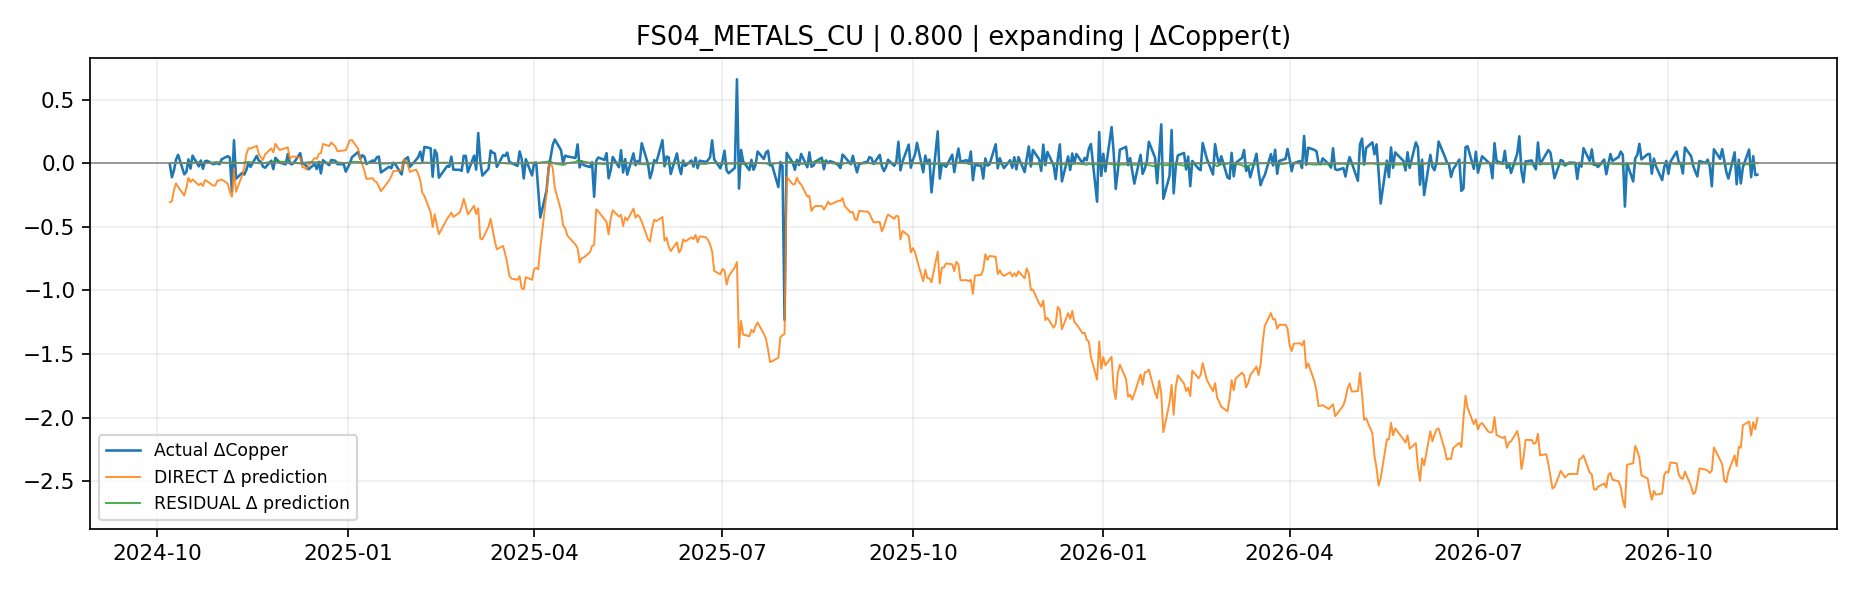


 delta_r0800_recency_weighted.png


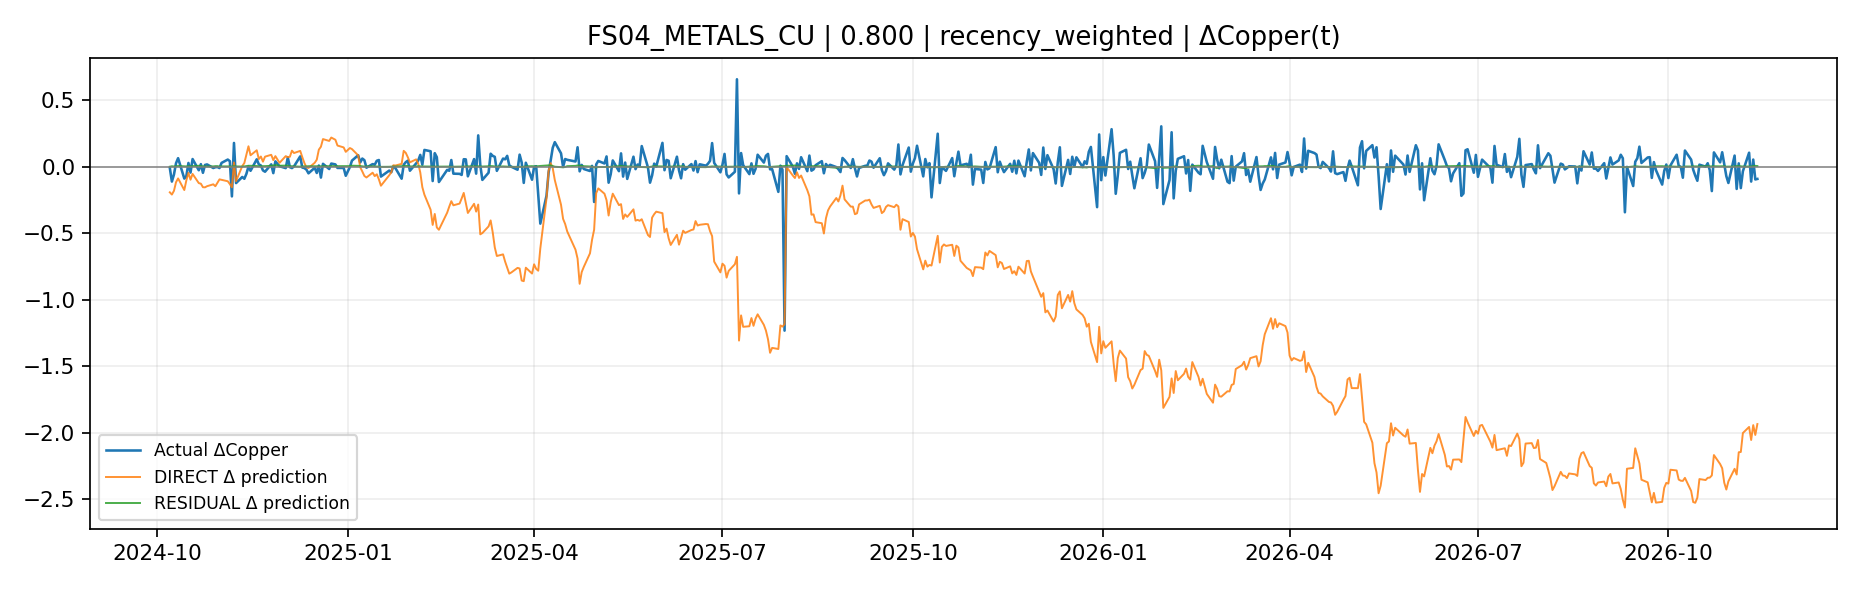


 delta_r0800_rolling_756.png


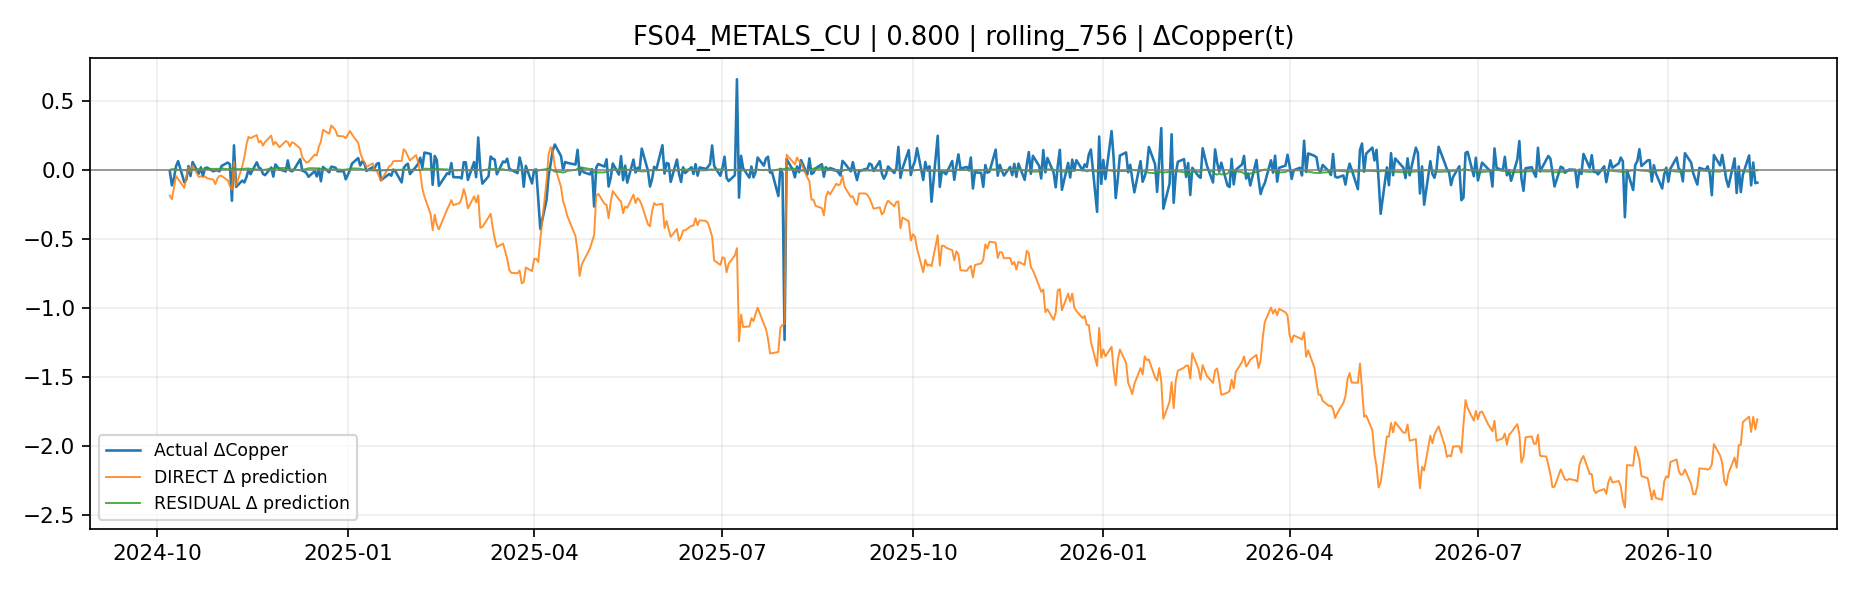


 delta_r0900_expanding.png


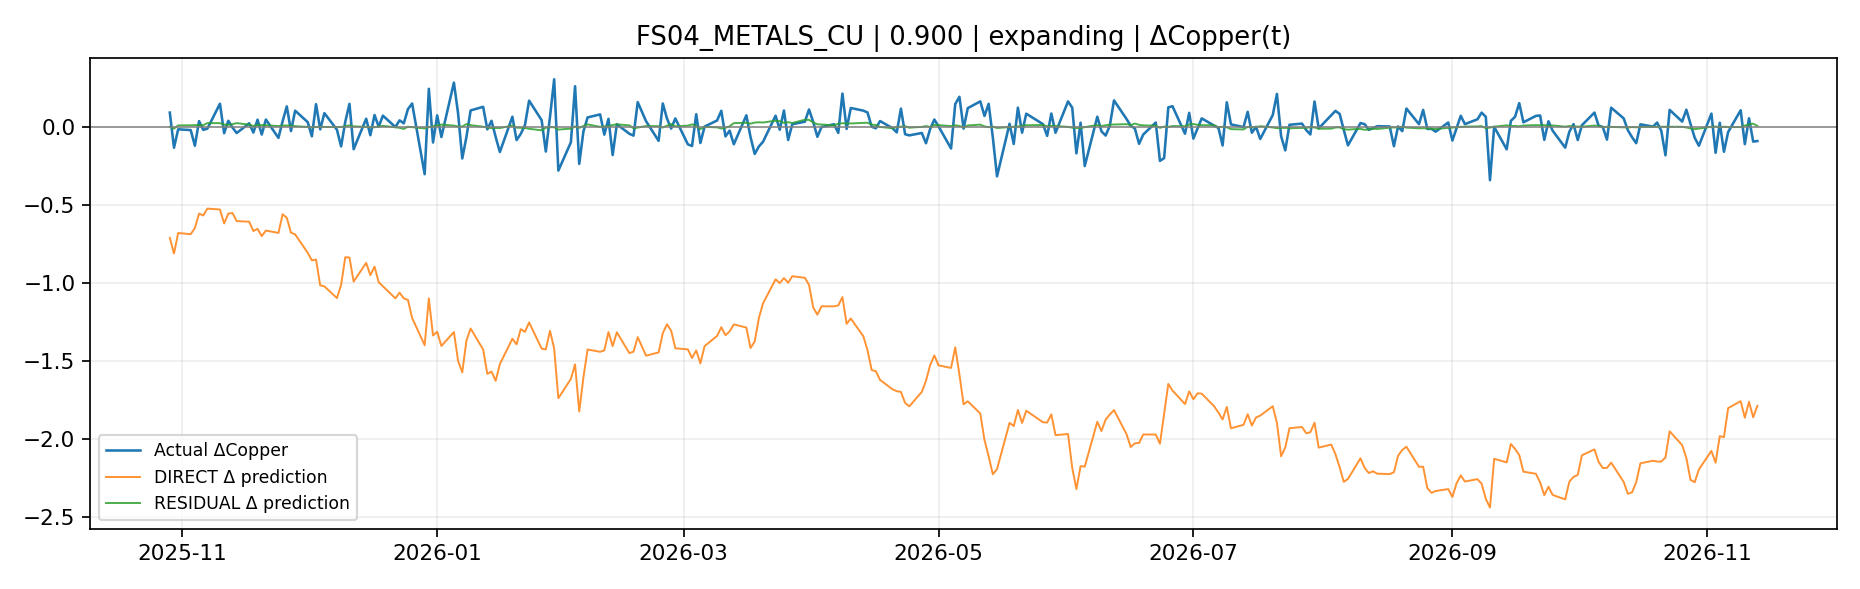


 delta_r0900_recency_weighted.png


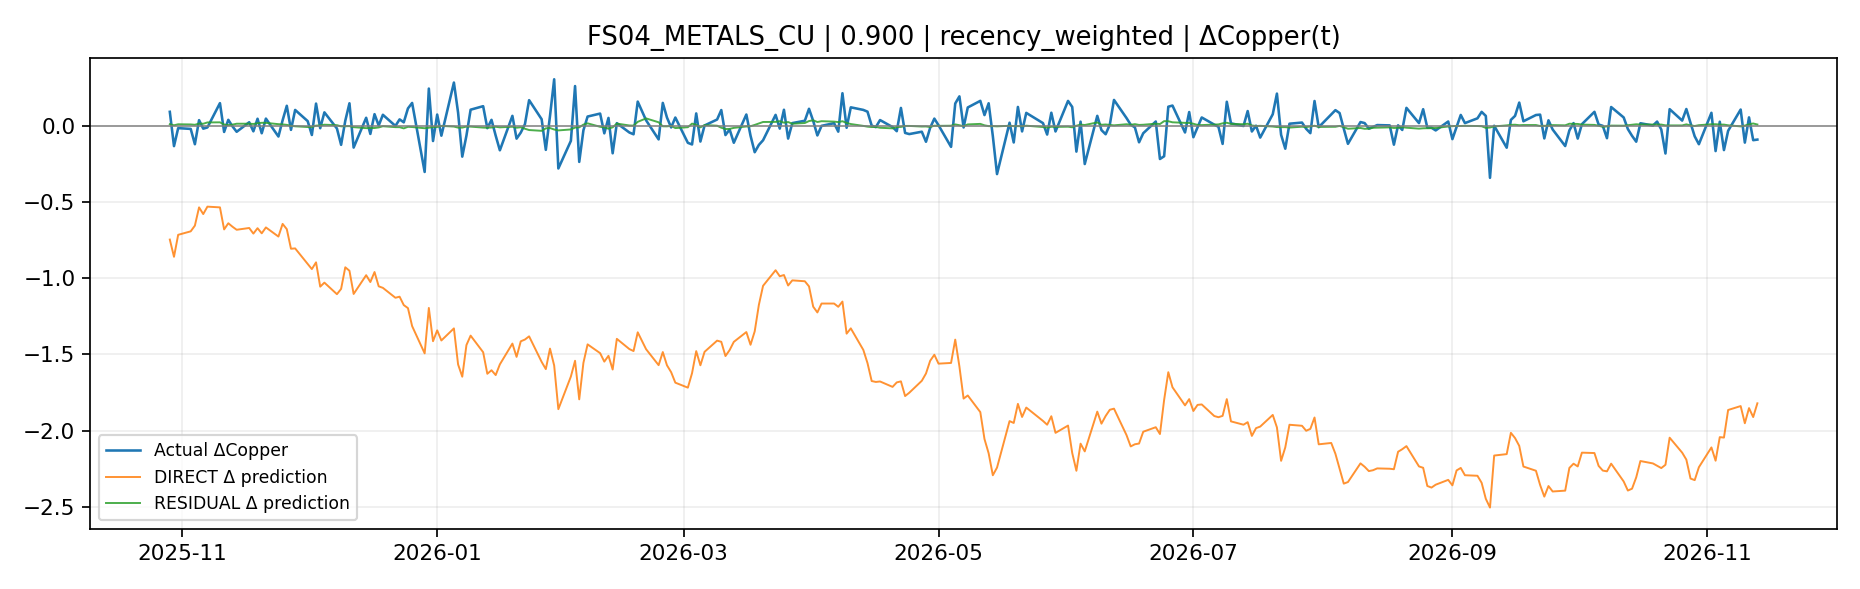


 delta_r0900_rolling_756.png


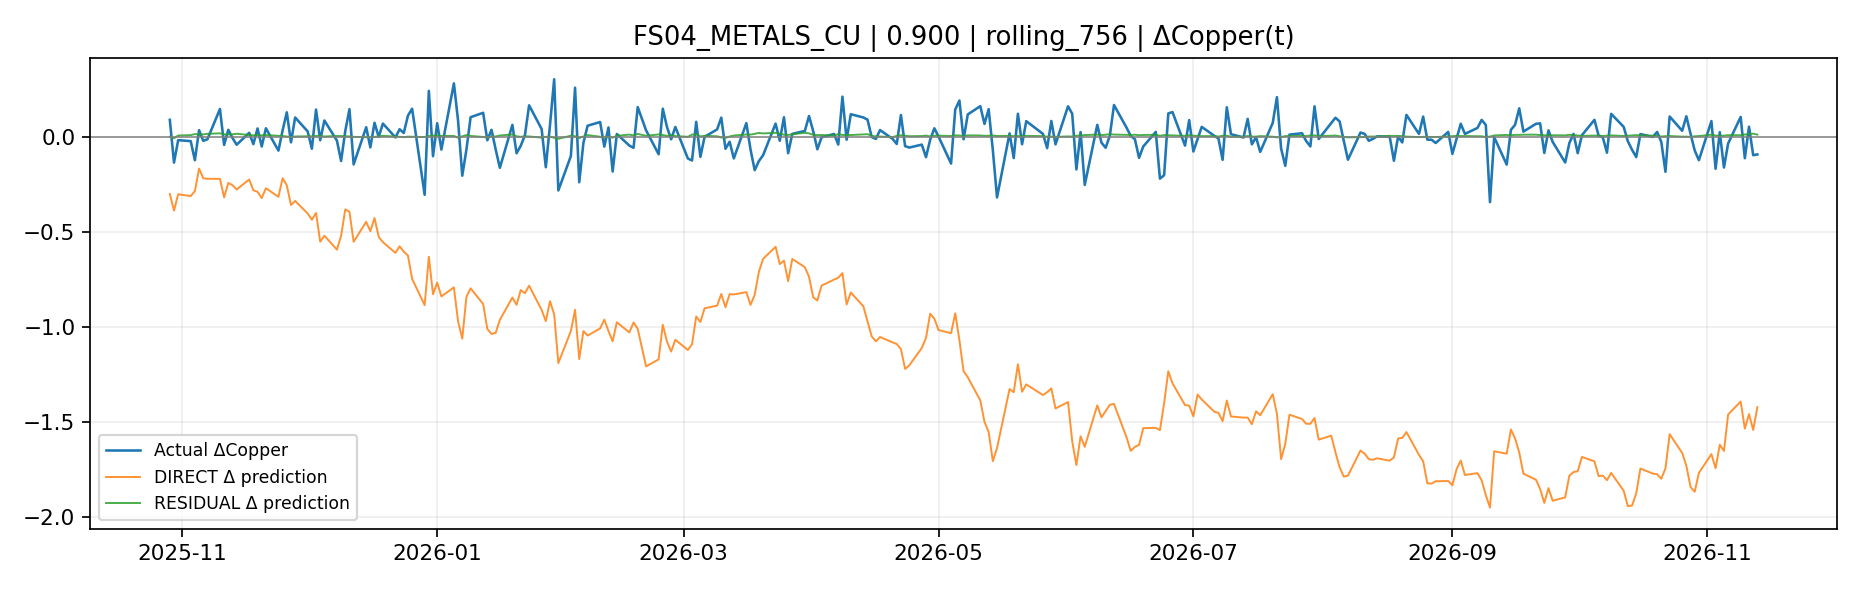


 delta_r0925_expanding.png


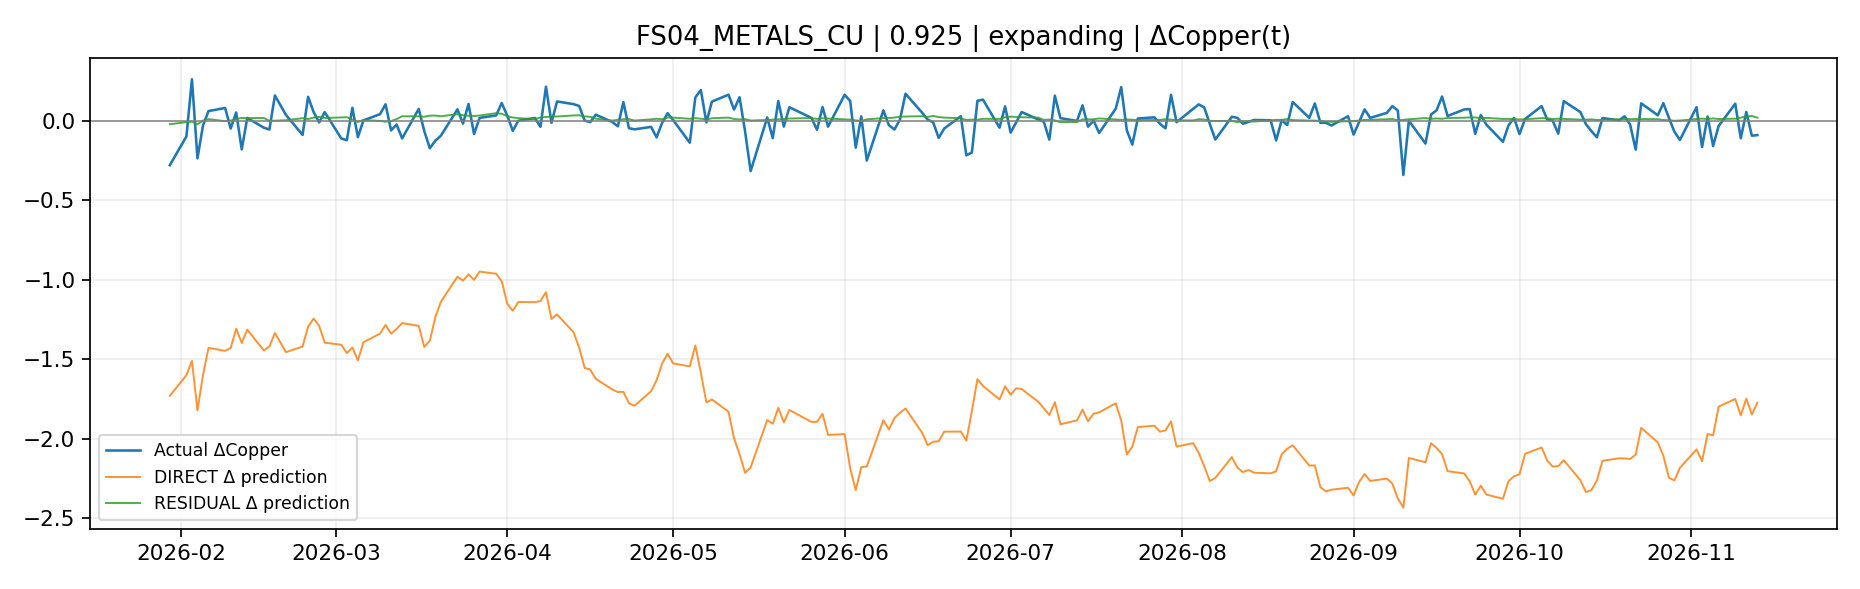


 delta_r0925_recency_weighted.png


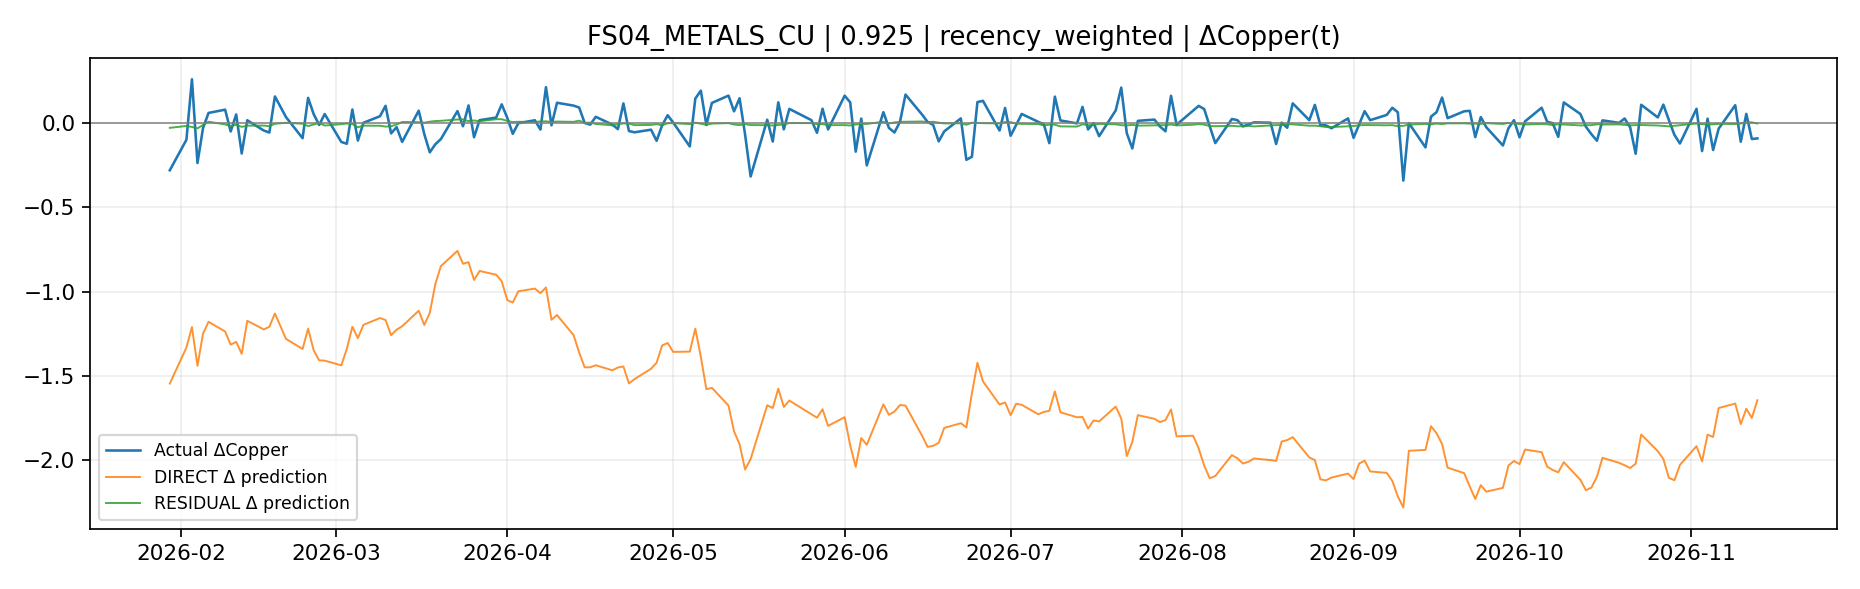


 delta_r0925_rolling_756.png


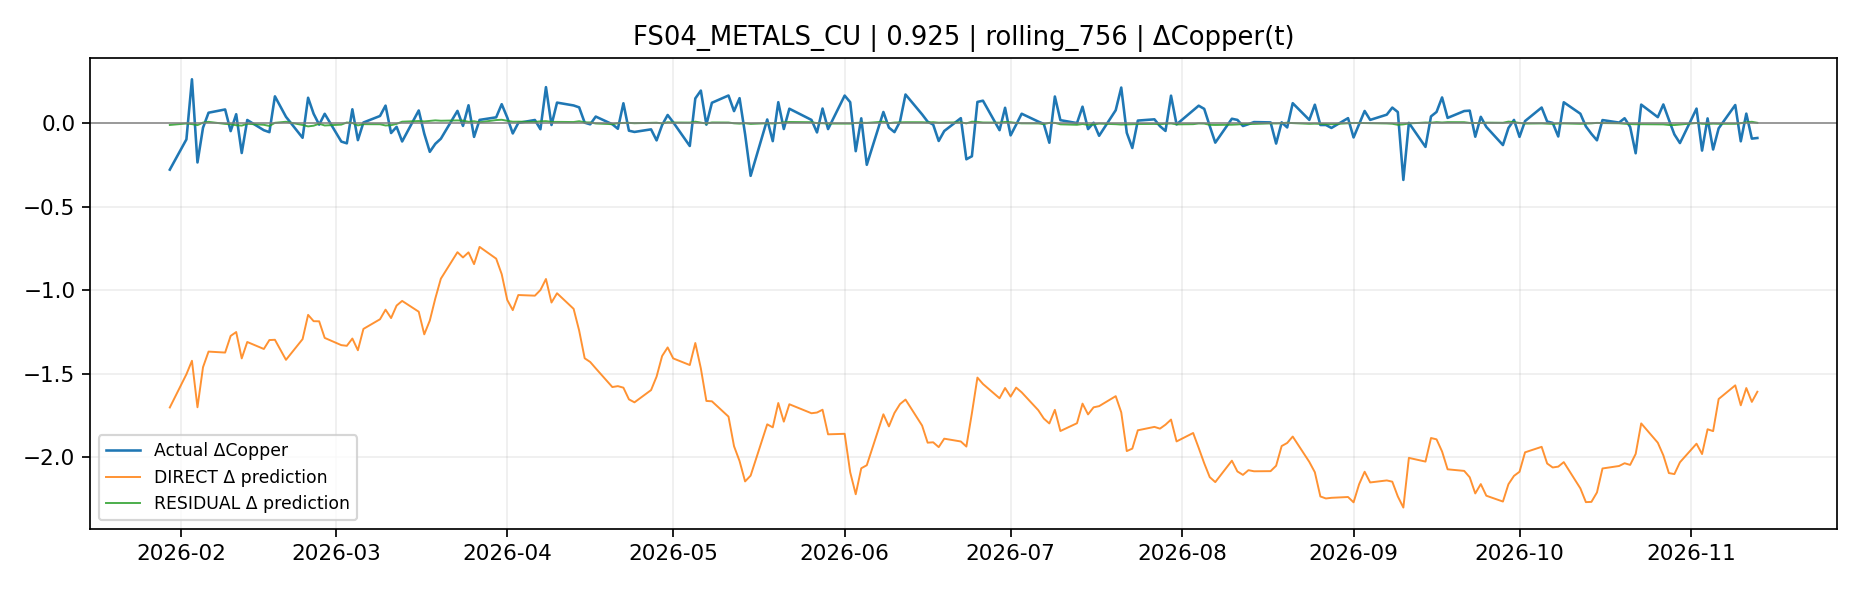


 delta_r0950_expanding.png


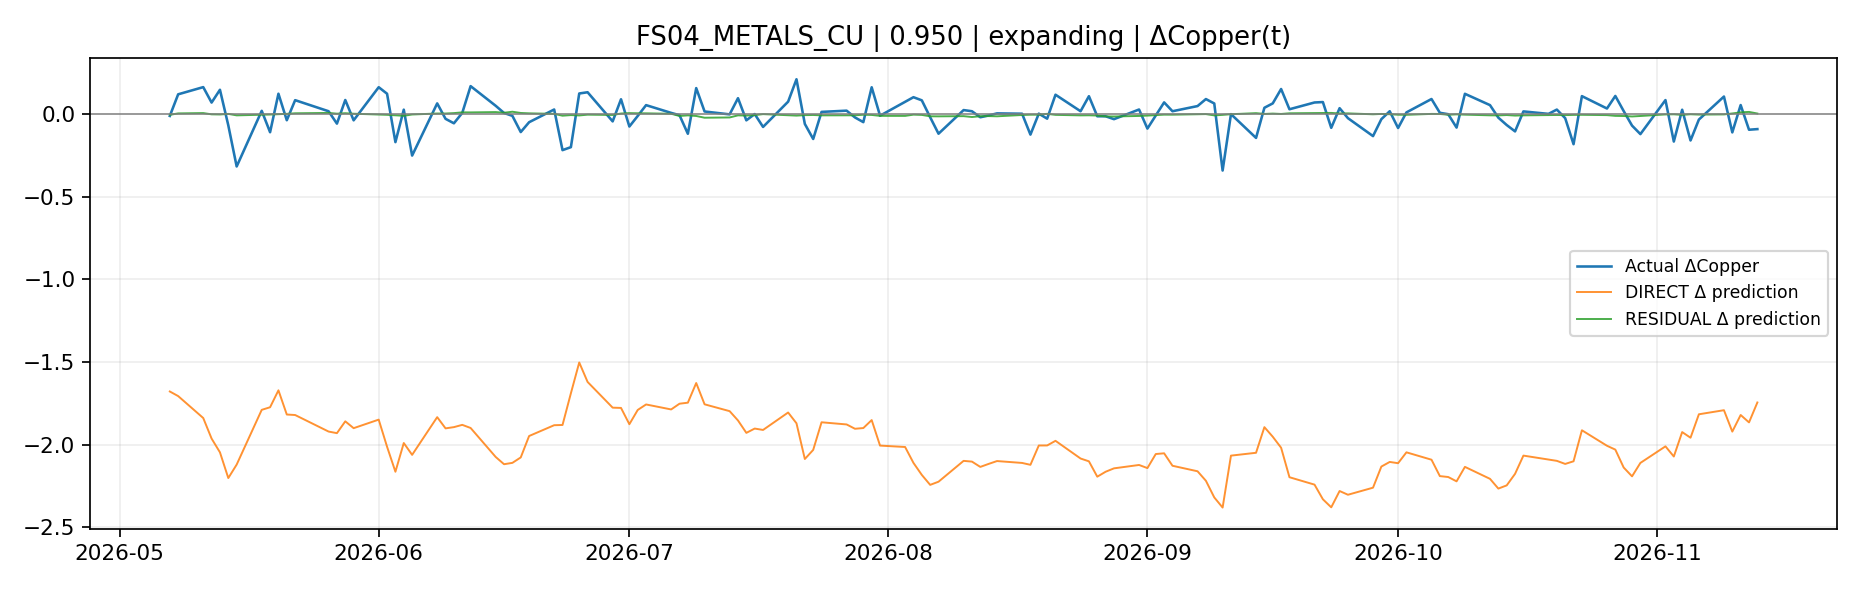


 delta_r0950_recency_weighted.png


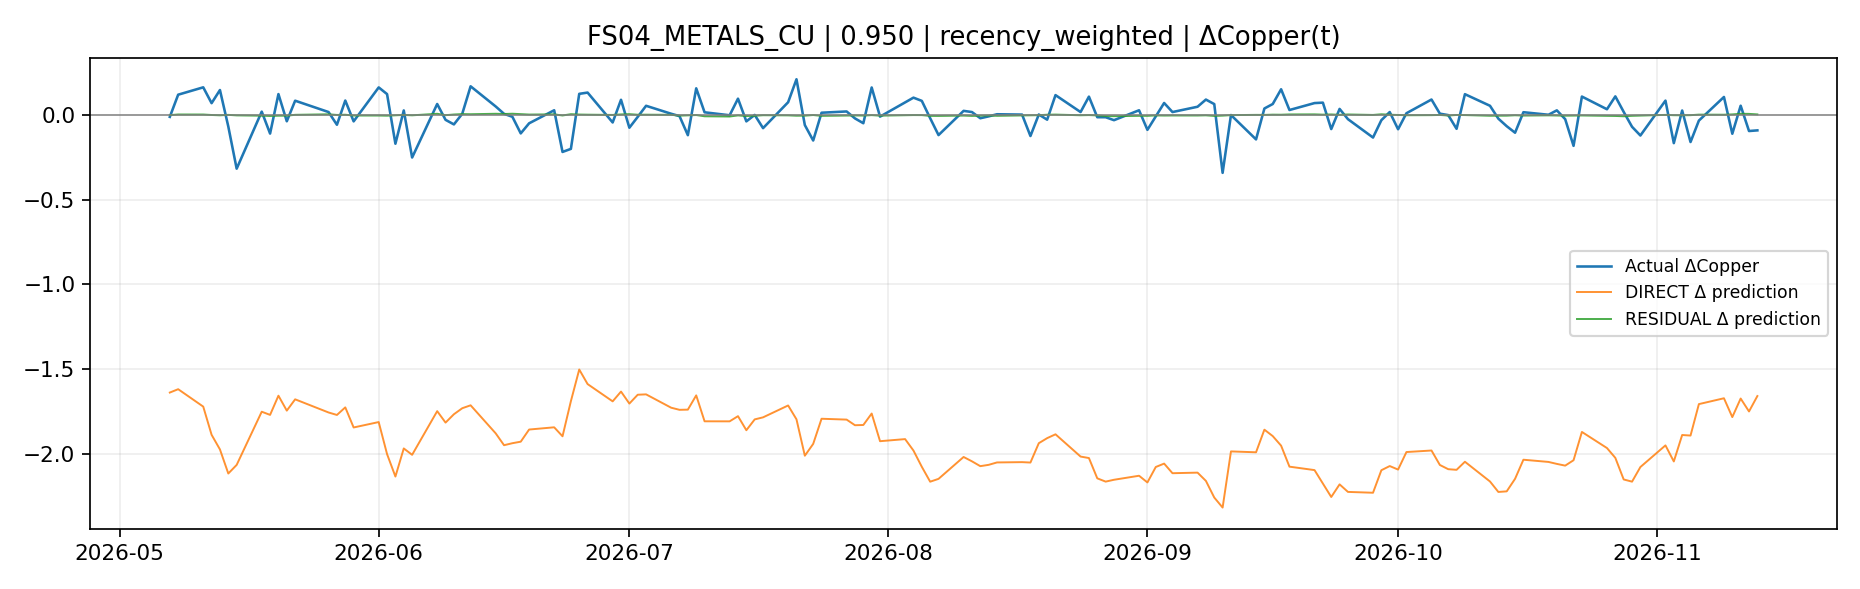


 delta_r0950_rolling_756.png


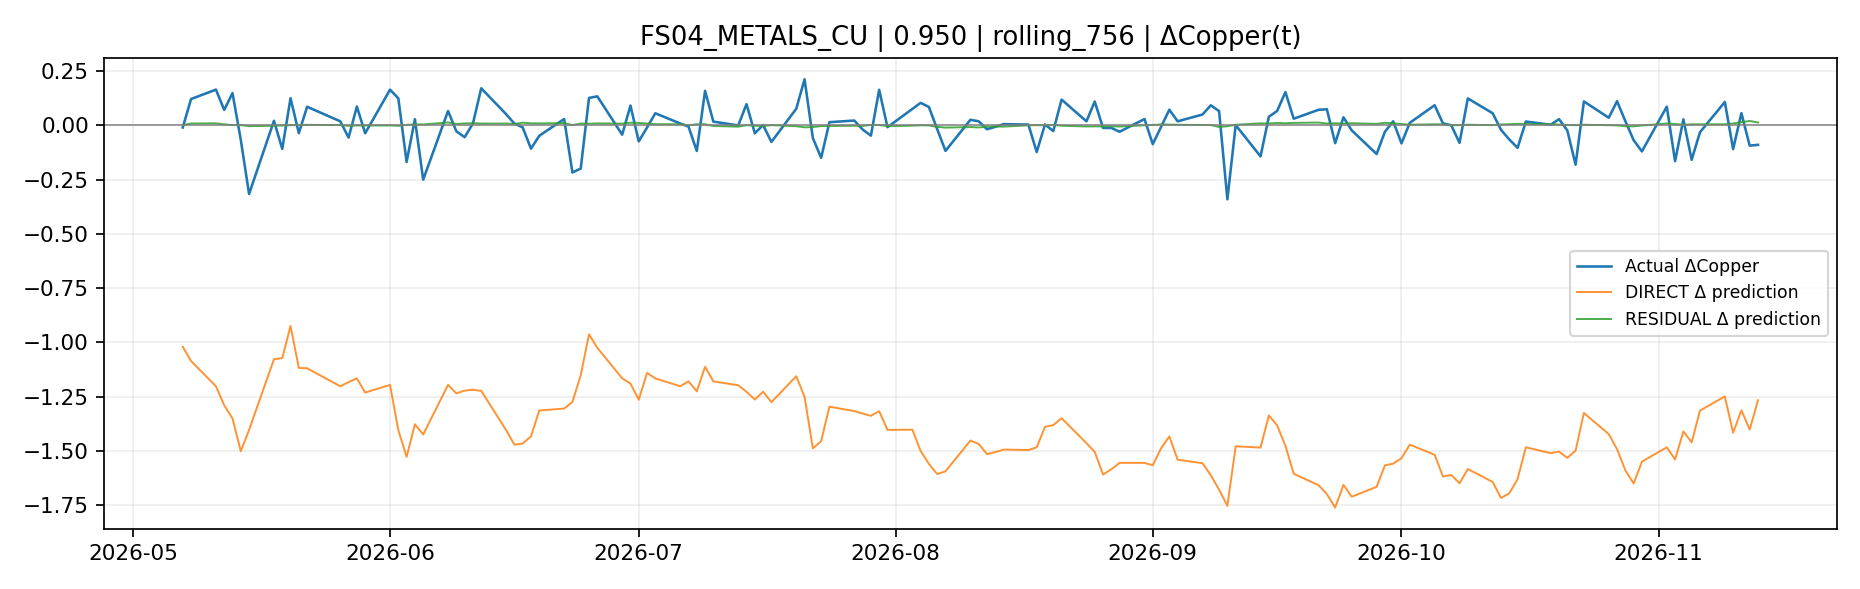


 prices_r0800_expanding.png


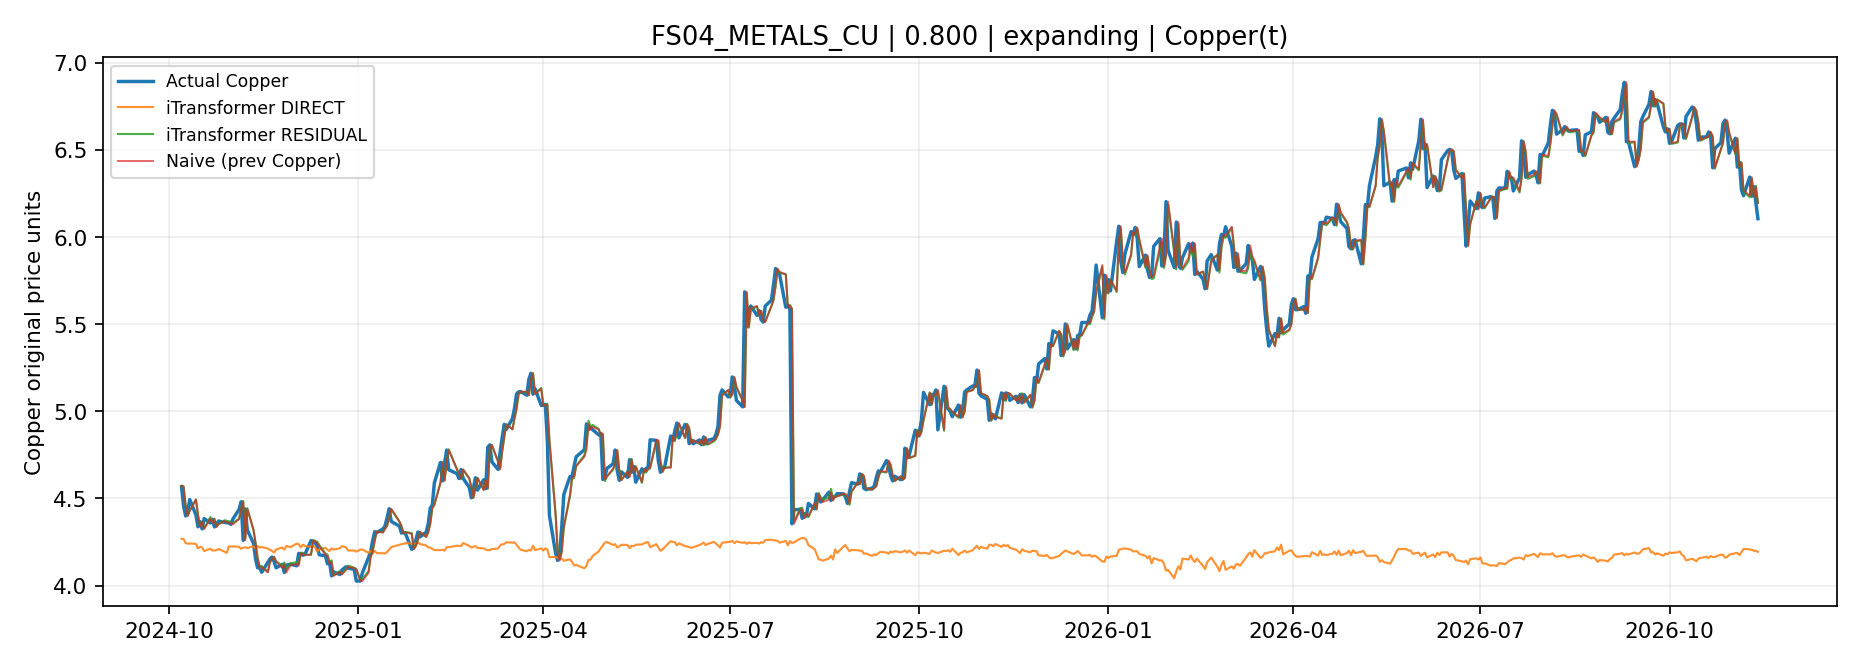


 prices_r0800_recency_weighted.png


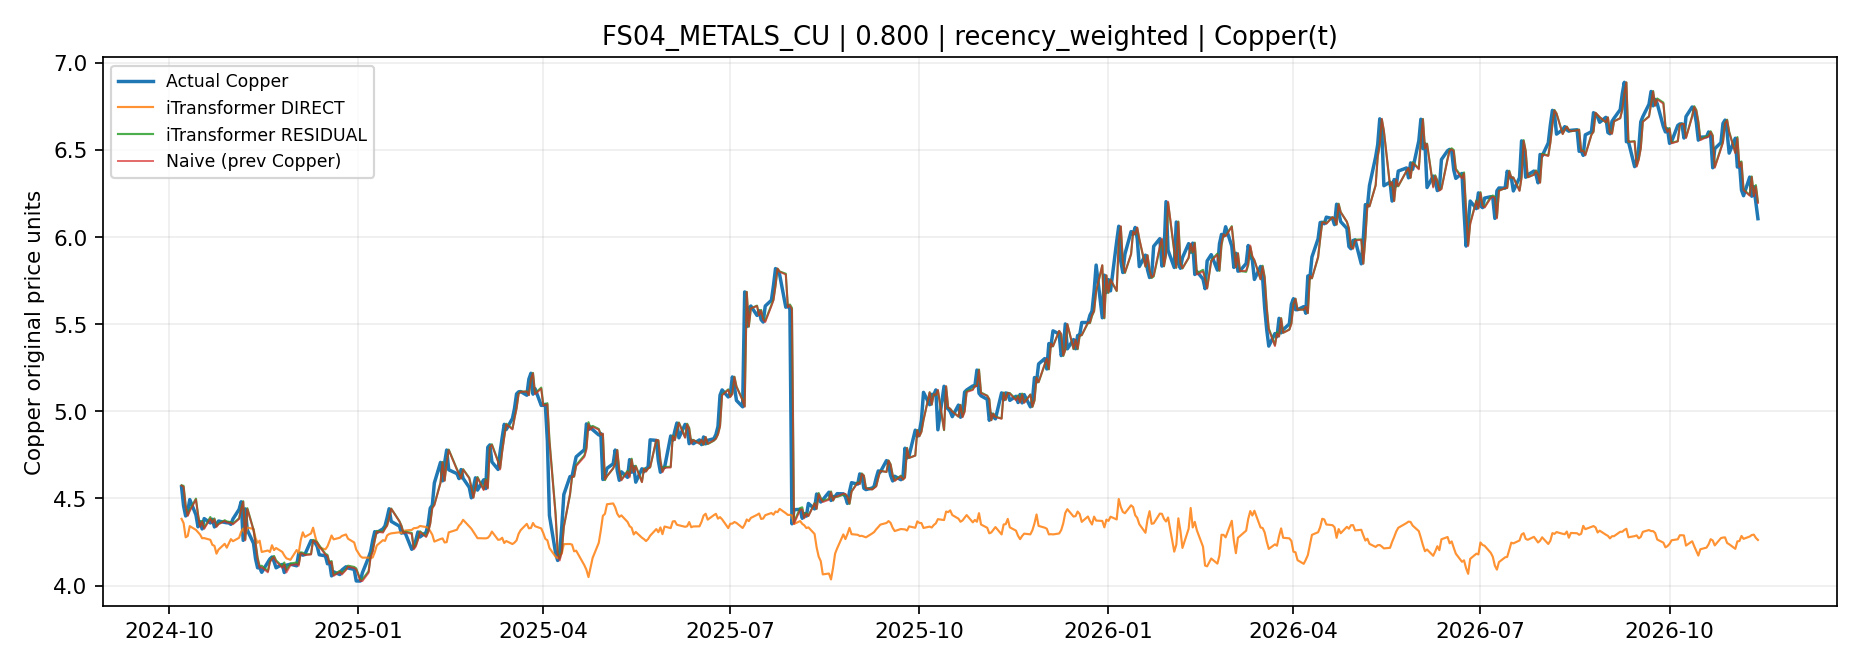


 prices_r0800_rolling_756.png


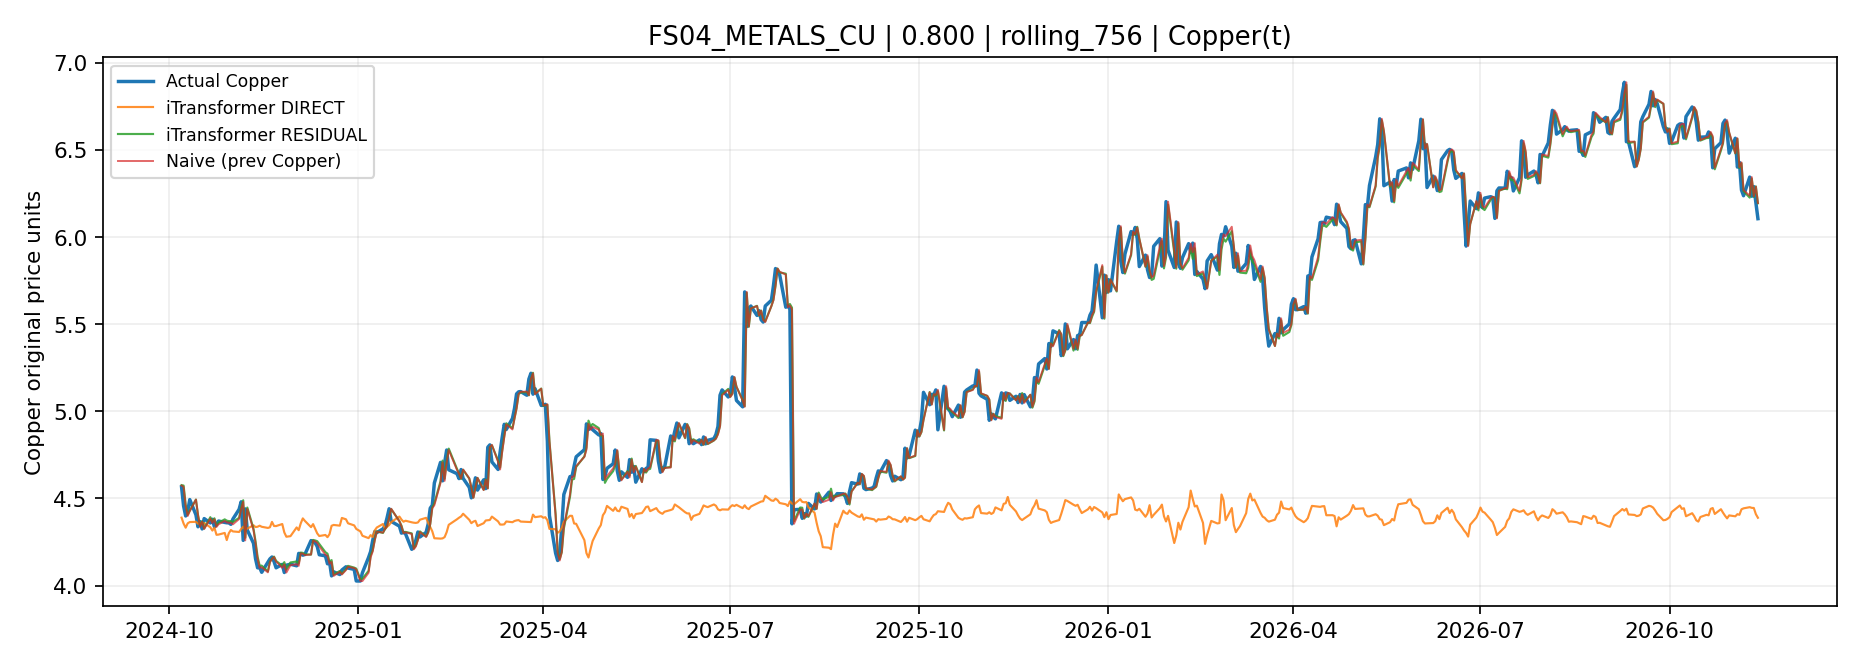


 prices_r0900_expanding.png


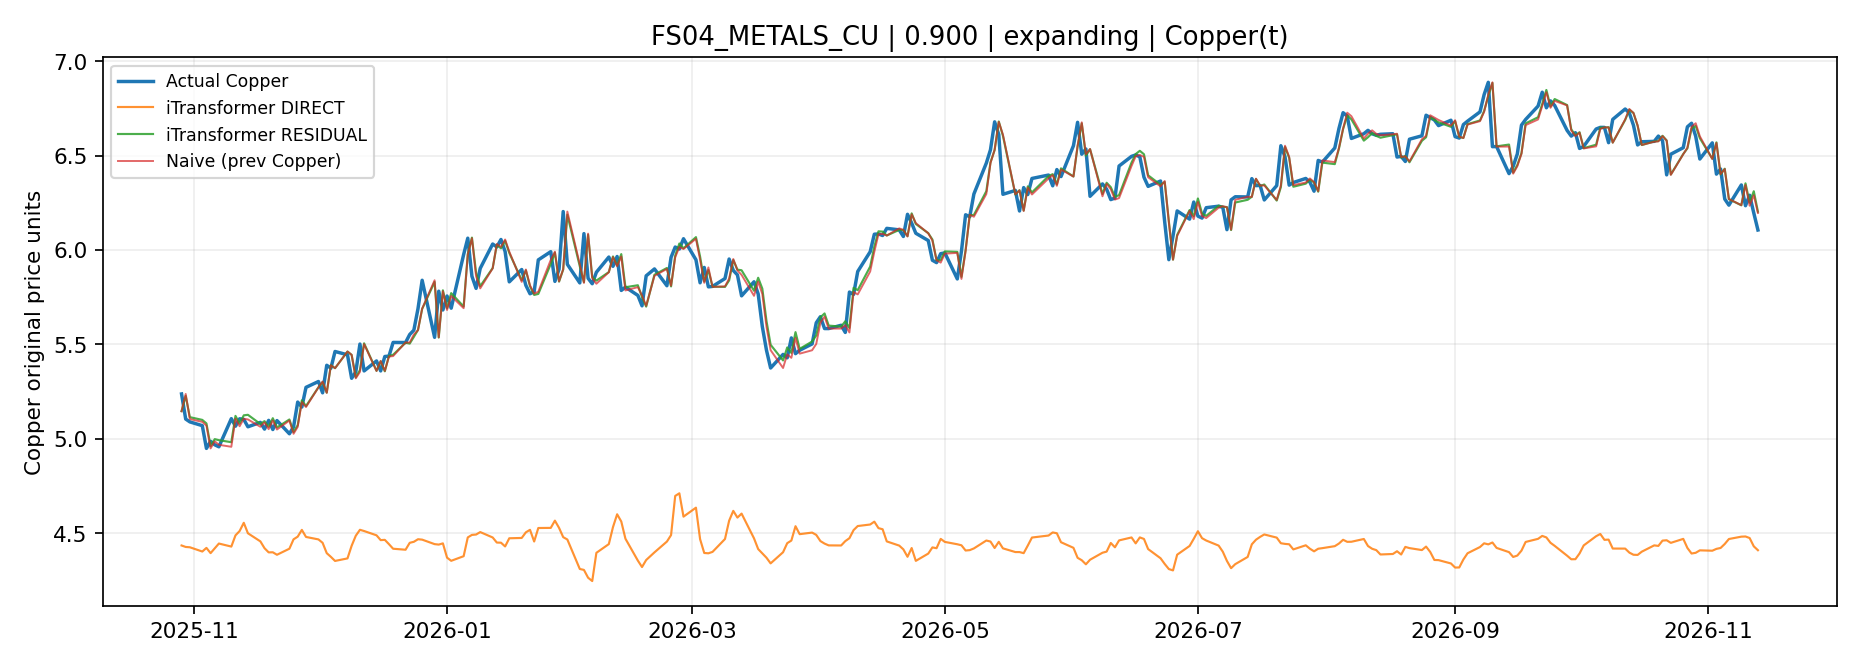


 prices_r0900_recency_weighted.png


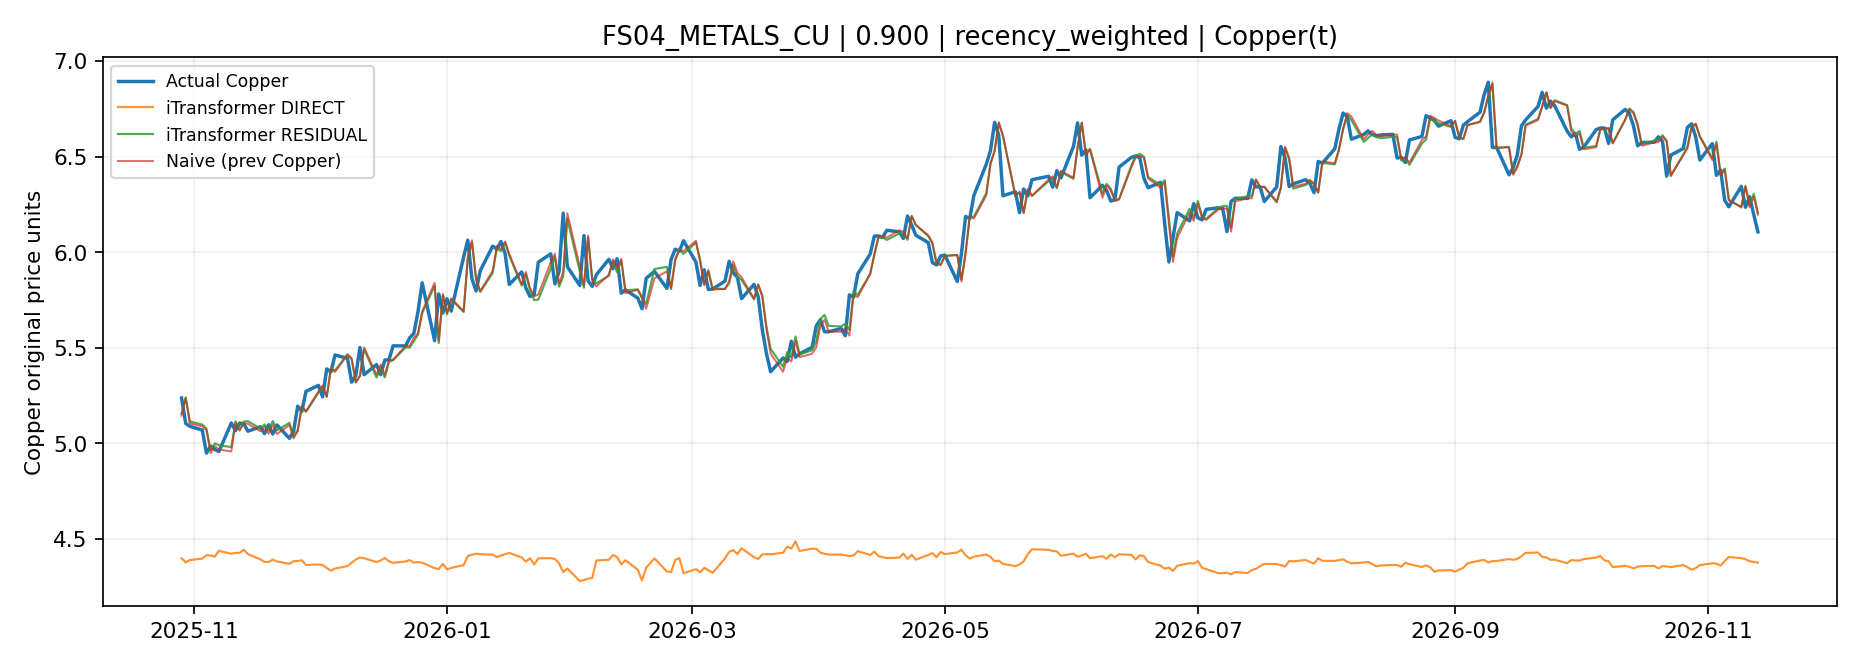


 prices_r0900_rolling_756.png


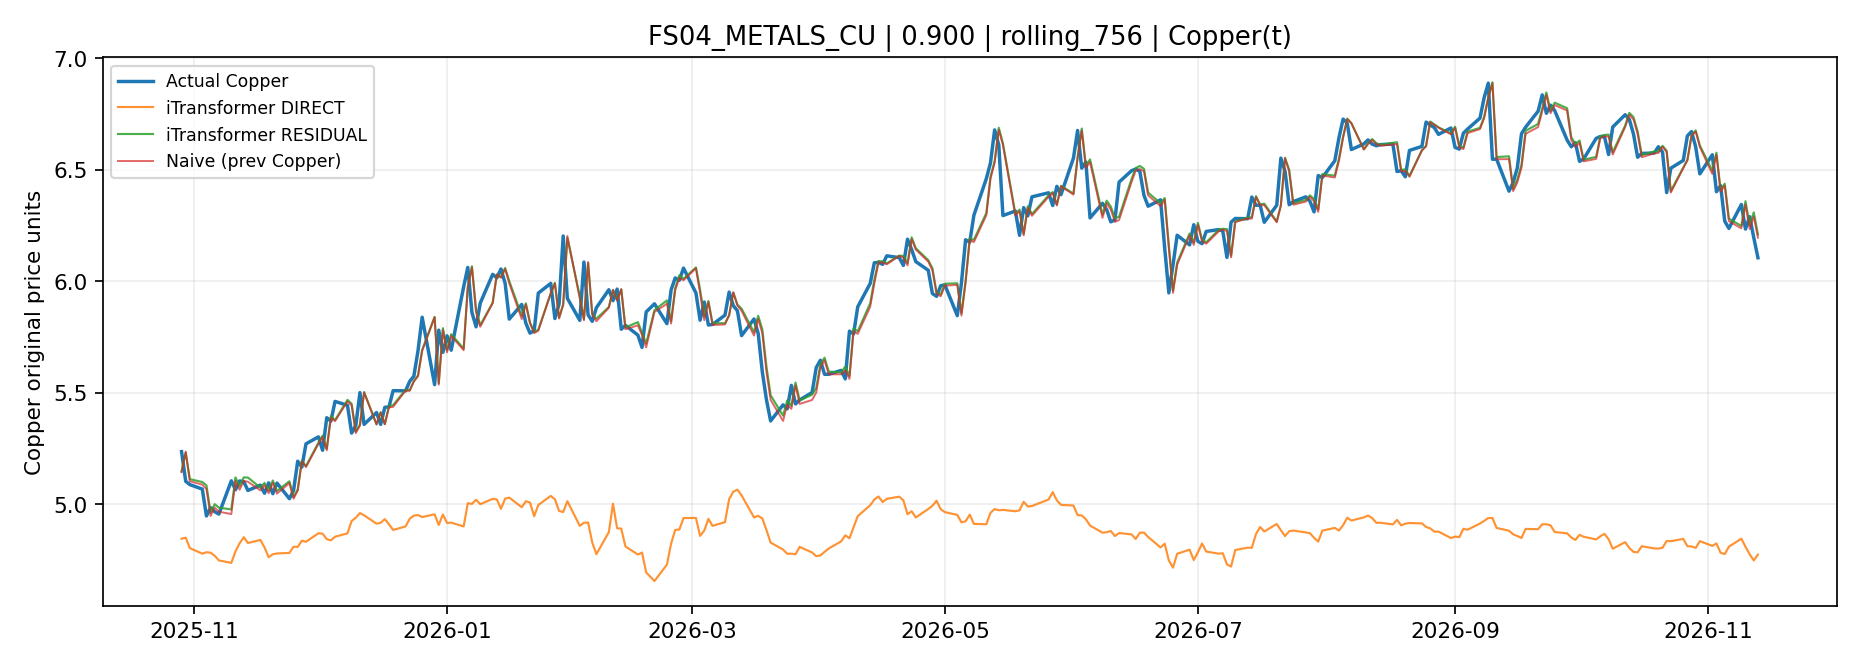


 prices_r0925_expanding.png


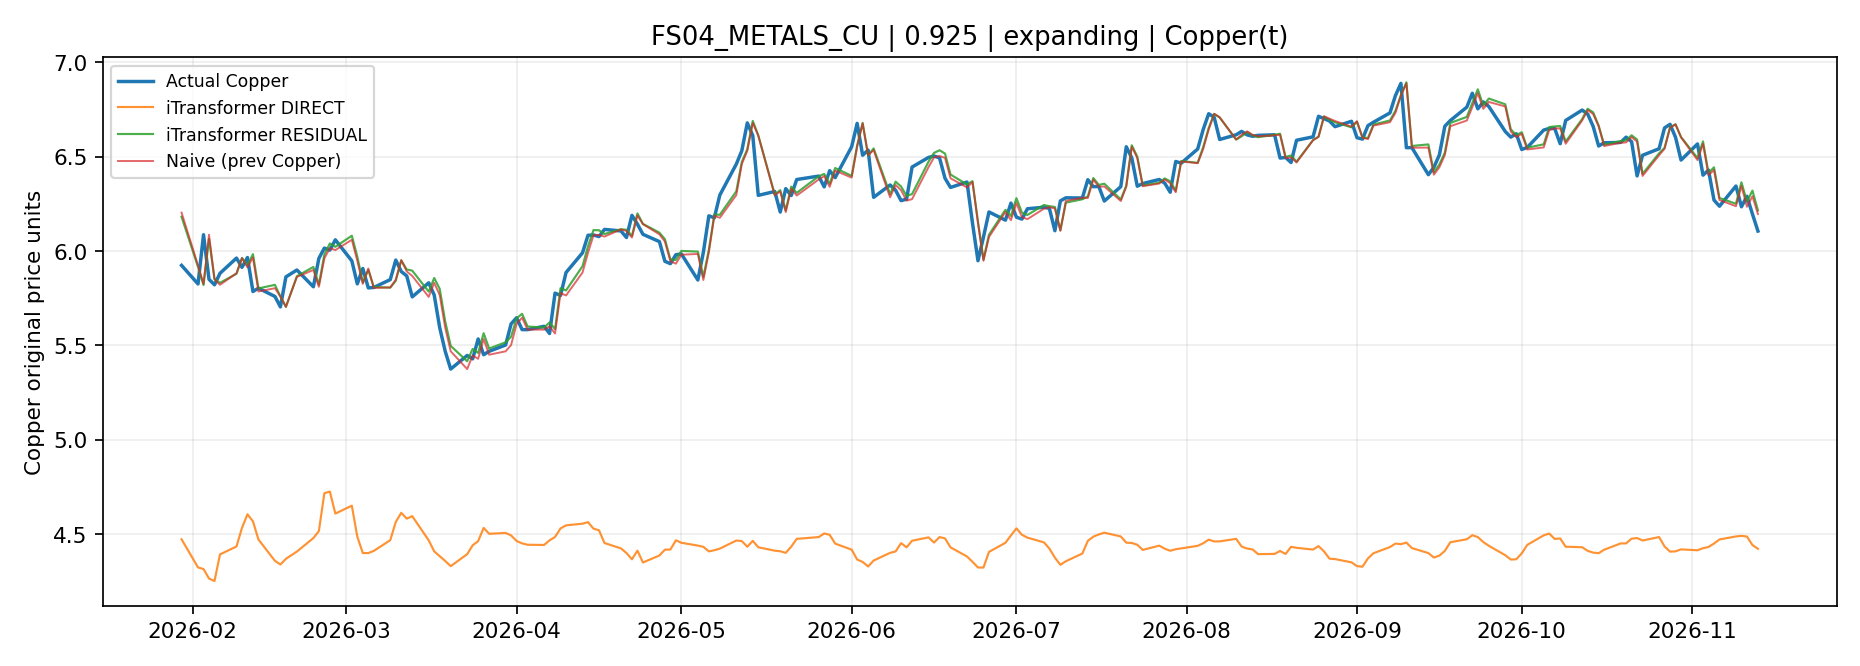


 prices_r0925_recency_weighted.png


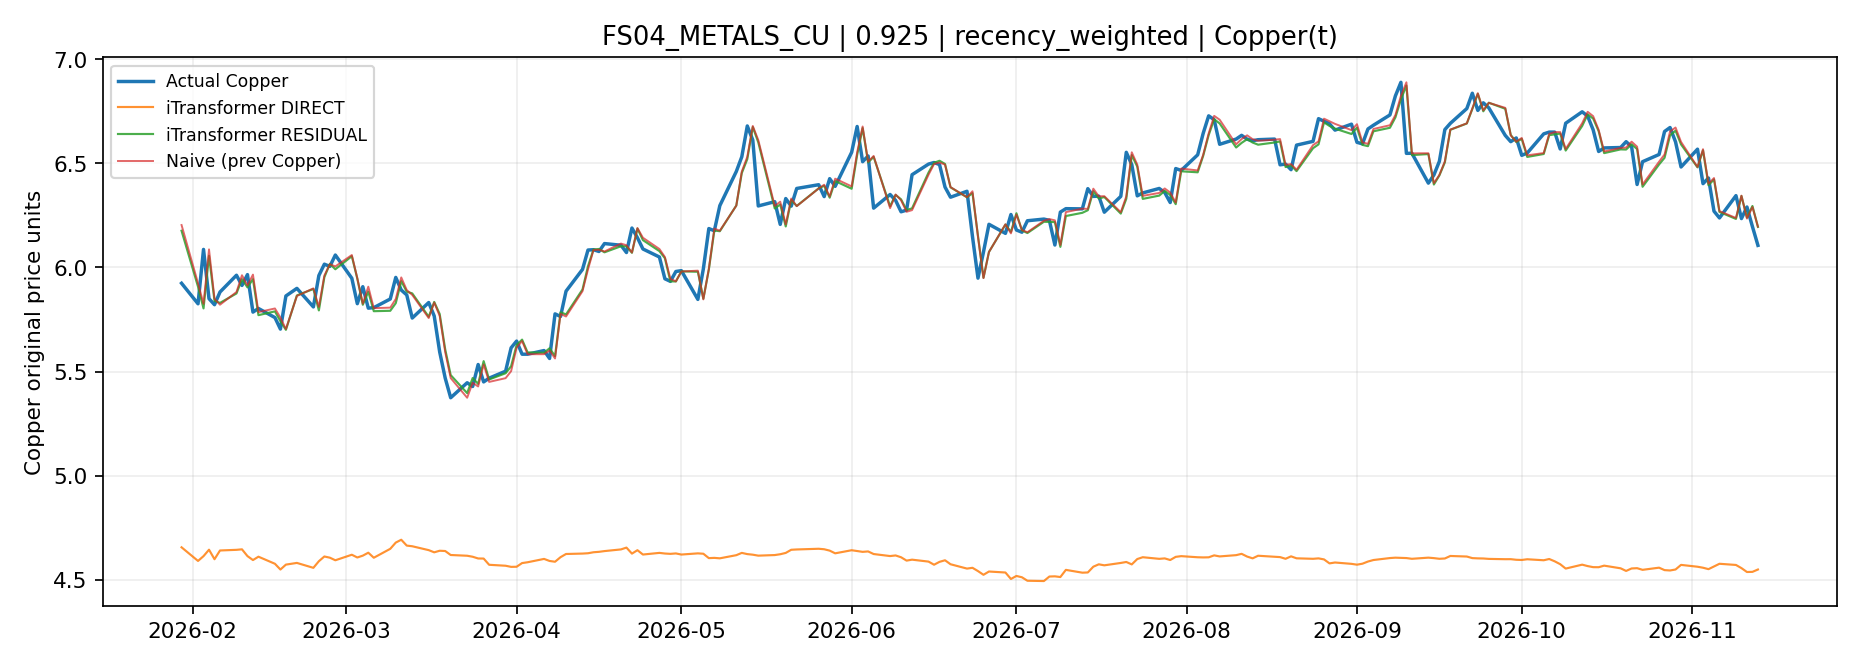


 prices_r0925_rolling_756.png


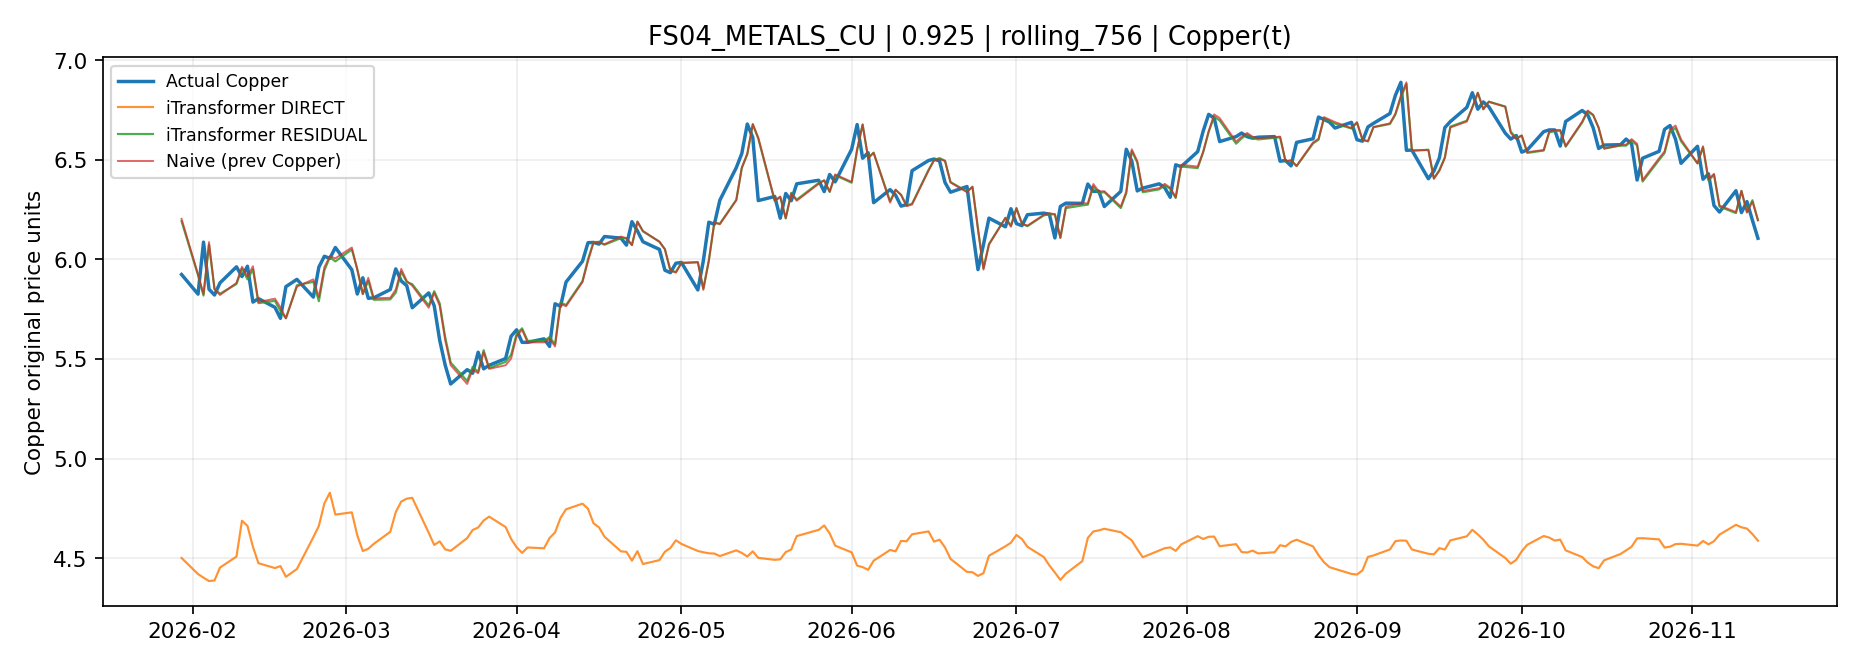


 prices_r0950_expanding.png


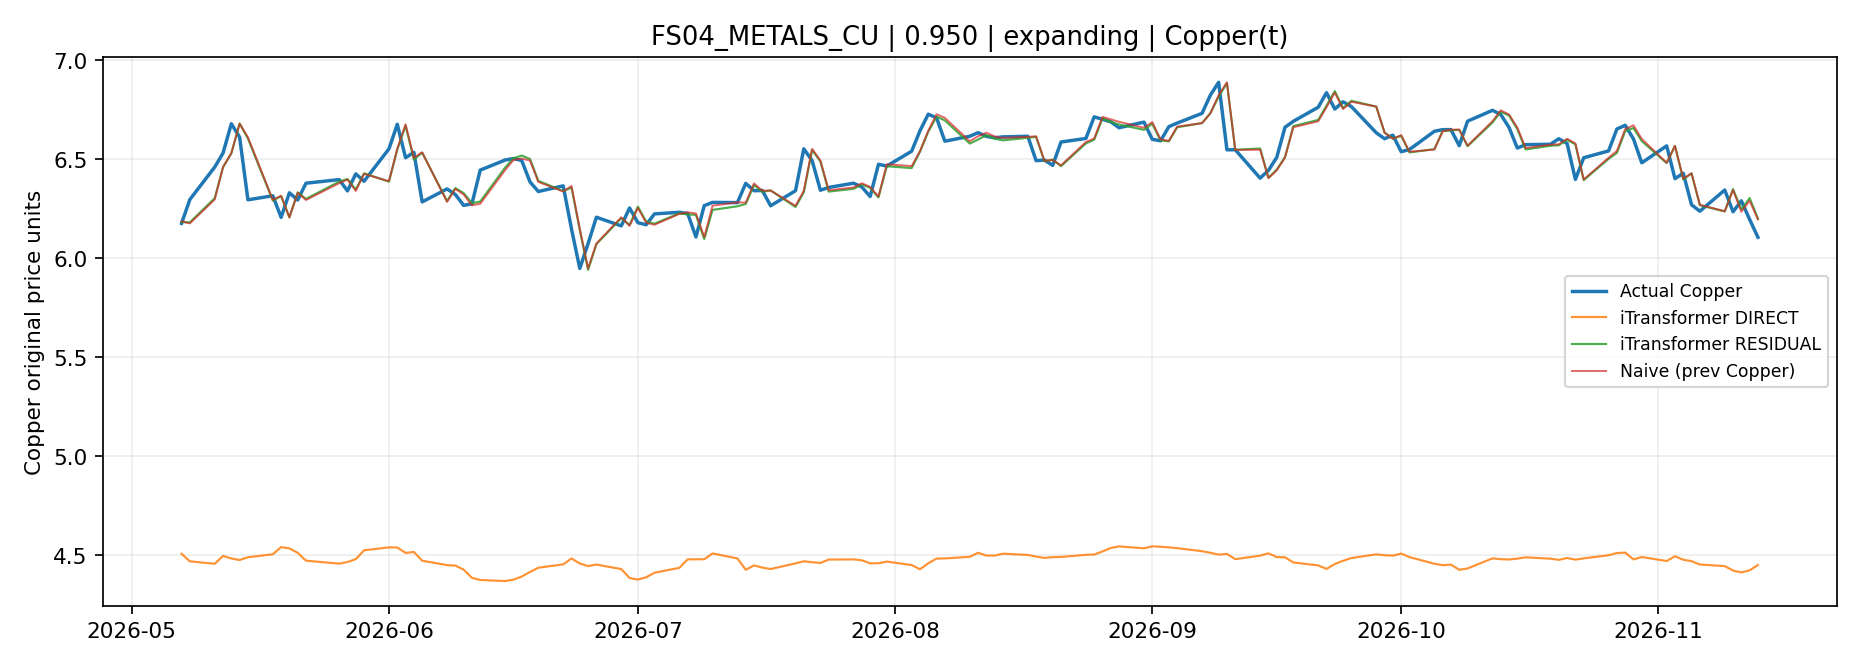


 prices_r0950_recency_weighted.png


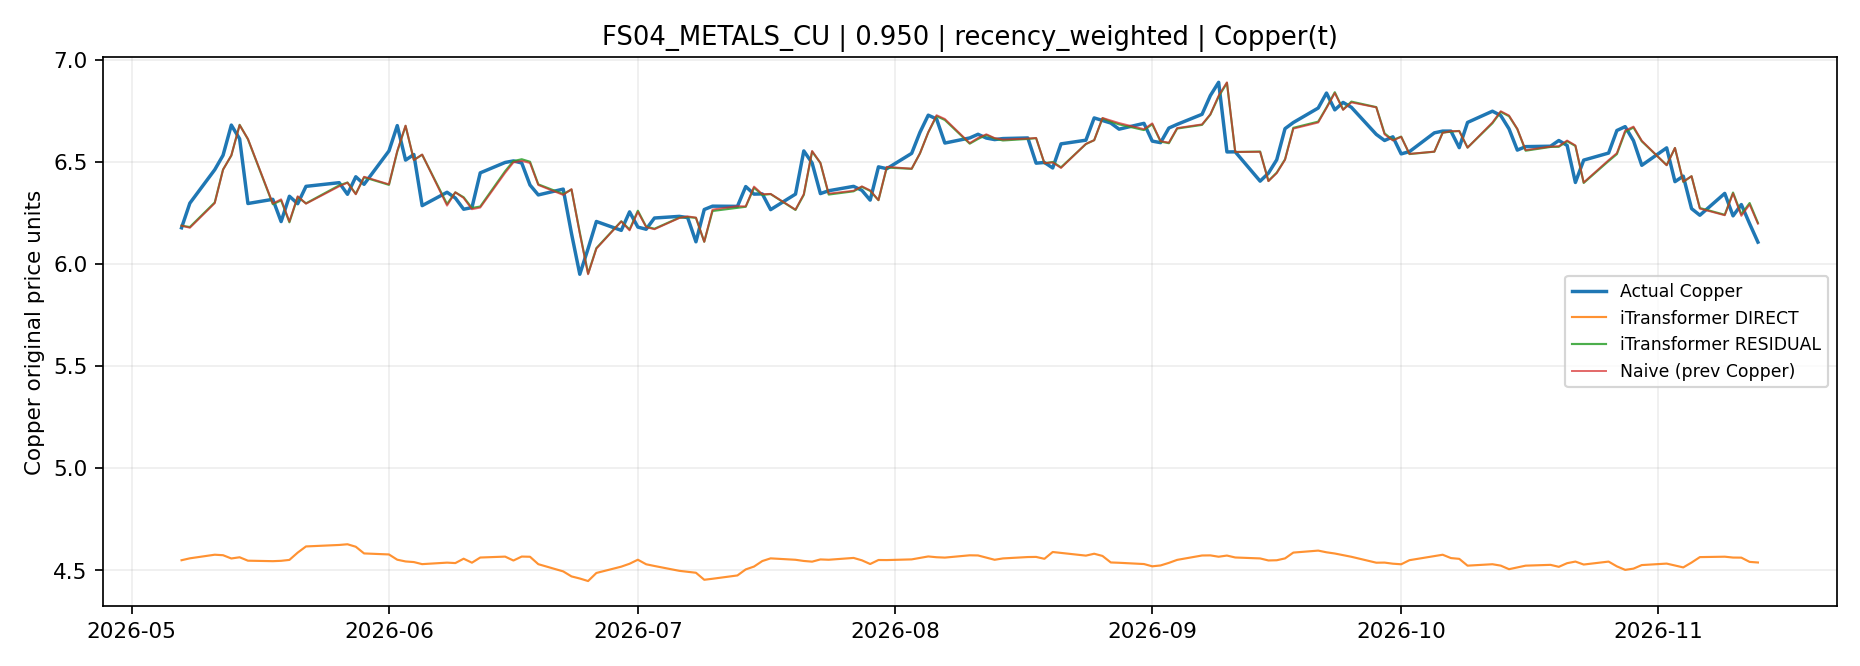


 prices_r0950_rolling_756.png


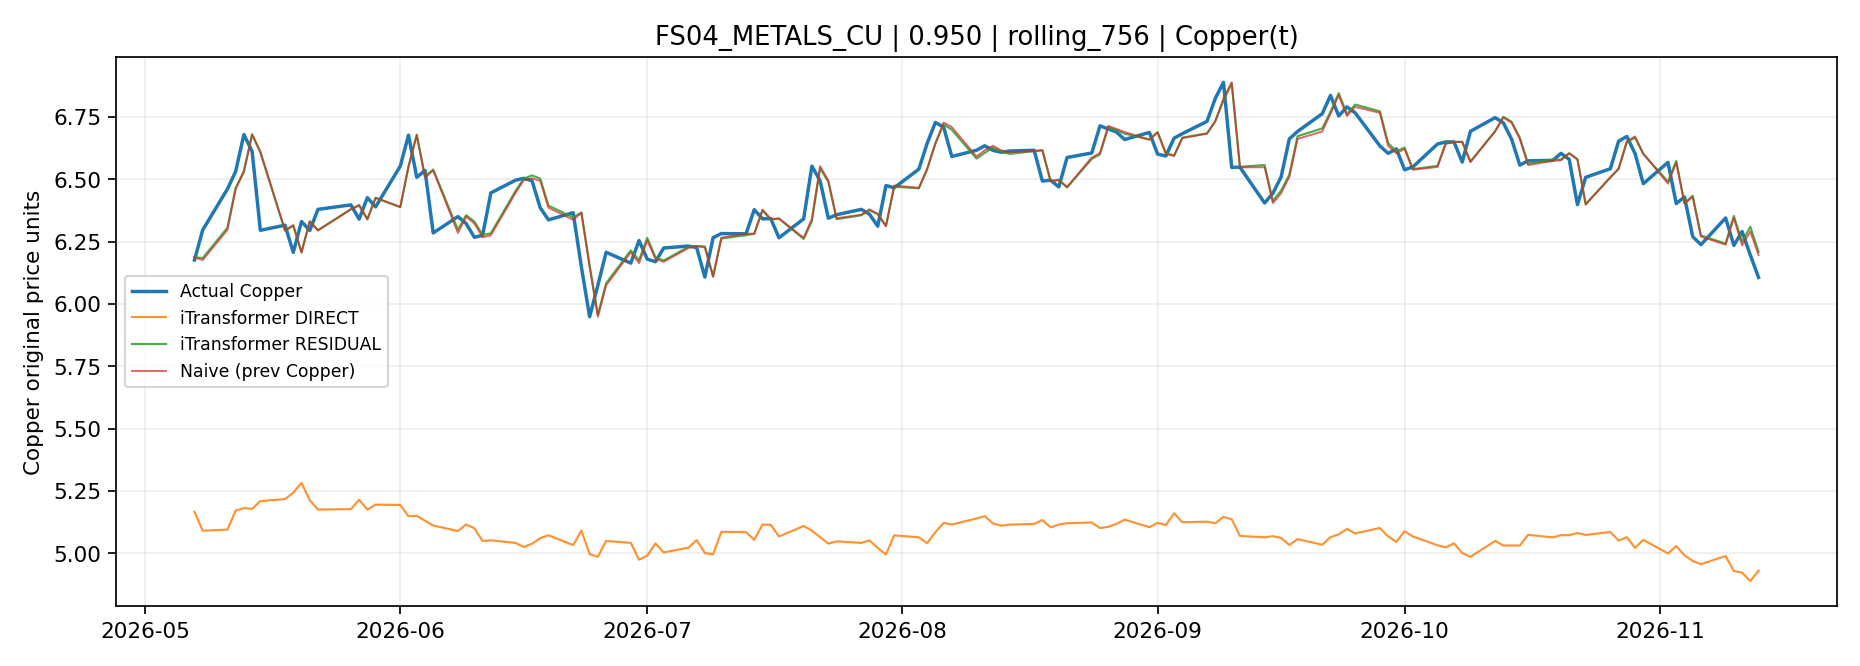

In [10]:
from IPython.display import display, Image
from pathlib import Path

fig_dir = OUT / "figures"
images = sorted(fig_dir.glob("*.png"))

print(f"Tổng số biểu đồ: {len(images)}")

for img in images:
    print("\n", img.name)
    display(Image(filename=str(img), width=1100))


## 9. Xuất manifest và ZIP tải từ Kaggle

In [9]:
# Final manifests, test date checks, ZIP in /kaggle/working for download.
summary={
    'feature_set':FEATURE_SET_ID,'features':FEATURES,'K':len(FEATURES),
    'run_key':RUN_KEY,'data_sha256':DATA_SHA256,
    'n_rows':len(data),'min_date':str(data.Date.min().date()),
    'max_date':str(data.Date.max().date()),
    'results_rows':len(results), 'predictions_rows':len(preds),
    'expected_rows':len(EXPECTED),'date_ranges':{},
    'note':'Test set is trailing chronological segment. Val is last 10% of pre-test period; scaler fit only on earlier train.'
}
for ratio in RATIOS:
    c=make_context(data,ratio,'expanding')
    summary['date_ranges'][str(ratio)]={
        'test_start':str(pd.Timestamp(c['test']['date'][0]).date()),
        'test_end':str(pd.Timestamp(c['test']['date'][-1]).date()),
        'test_n':len(c['test']['idx'])}
(OUT/'manifest.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding='utf-8')
# Toàn bộ kết quả ở cùng output của notebook, ZIP không chứa model .keras mặc định.
ZIP_FILE=OUT.parent/(f'{FEATURE_SET_ID}_iTransformer_{MODE}_{RUN_KEY[-12:]}.zip')
with zipfile.ZipFile(ZIP_FILE,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=6) as z:
    for f in OUT.rglob('*'):
        if not f.is_file(): continue
        if f.suffix=='.keras' and not INCLUDE_MODELS_IN_ZIP: continue
        z.write(f,arcname=str(Path(FEATURE_SET_ID)/f.relative_to(OUT)))
print('READY - PLEASE DOWNLOAD THIS FILE FROM KAGGLE OUTPUT:')
print(ZIP_FILE)
print('Main CSV:',OUT/'grid_results.csv',OUT/'grid_predictions.csv')
print('Send ZIP + notebook outputs to compare all FS01..FS06 with Khoa.')


READY - PLEASE DOWNLOAD THIS FILE FROM KAGGLE OUTPUT:
/kaggle/working/iTransformer_Module1_6FS/FS04_METALS_CU/FS04_METALS_CU_iTransformer_FULL_bd12631cf50d.zip
Main CSV: /kaggle/working/iTransformer_Module1_6FS/FS04_METALS_CU/FULL_FS04_METALS_CU_s42_shaa761a908_bd12631cf50d/grid_results.csv /kaggle/working/iTransformer_Module1_6FS/FS04_METALS_CU/FULL_FS04_METALS_CU_s42_shaa761a908_bd12631cf50d/grid_predictions.csv
Send ZIP + notebook outputs to compare all FS01..FS06 with Khoa.


### Kiểm tra trước khi so sánh với Khoa

- Đối chiếu hash CSV và ngày test của từng split; nếu khác, **không so sánh MAE như thể cùng dữ liệu**.
- Trên cùng FS/split/scheme so sánh `itransformer_direct`, `itransformer_residual` với `naive` trên cùng timestamp; khi gửi kết quả có thể ghép theo `(Date, ratio, scheme)` để kiểm định paired/HAC.
- Residual dễ cho giá dự báo sát Actual nhờ Copper(t−1); xem cả `actual_delta`, `pred_delta`, `skill_vs_naive_pct` và Directional Accuracy.
- Đây là thí nghiệm 1-step-ahead dùng giá thật t−1 sau khi quan sát, **không phải** dự báo nhiều bước không cập nhật.
- Kết quả chưa được train trong file này. File ZIP xuất ra chỉ sau khi `Run All` trên Kaggle thành công.
